In [1]:
# ============================================================
# SHAKESENSE: MOTOR HEALTH MONITORING & PREDICTIVE MAINTENANCE
# ML Pipeline | KU Leuven Motor-Bearing Dataset
# ============================================================

PROJECT_NAME = "ShakeSense"
DATASET_NAME = "KU Leuven Motor-Bearing Dataset"

print("Project:", PROJECT_NAME)
print("Dataset:", DATASET_NAME)
print("Environment: Google Colab")

Project: ShakeSense
Dataset: KU Leuven Motor-Bearing Dataset
Environment: Google Colab


In [3]:
from google.colab import drive
drive.mount('/content/drive')

import os
import glob

BASE_DIR = "/content/drive/MyDrive/"
RAW_DIR = os.path.join(BASE_DIR, "ShakeSense")

csv_files = glob.glob(
    os.path.join(RAW_DIR, "**", "*.csv"),
    recursive=True
)

print("Total CSV files:", len(csv_files))

for f in sorted(csv_files):
    print(os.path.basename(f))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Total CSV files: 24
2faulty10rev.csv
2faulty20rev.csv
2faulty30rev.csv
2ideal10rev.csv
2ideal20rev.csv
2ideal30rev.csv
2idealweight10rev.csv
2idealweight20rev.csv
2idealweight30rev.csv
2misaligned10rev.csv
2misaligned20rev.csv
2misaligned30rev.csv
faulty10rev.csv
faulty20rev.csv
faulty30rev.csv
ideal10rev.csv
ideal20rev.csv
ideal30rev.csv
idealweight10rev.csv
idealweight20rev.csv
idealweight30rev.csv
misaligned10rev.csv
misaligned20rev.csv
misaligned30rev.csv


In [4]:
import pandas as pd
import numpy as np
import os

audit_results = []

for file in sorted(csv_files):

    df = pd.read_csv(
        file,
        sep=';',
        header=None
    )

    audit_results.append({
        "filename": os.path.basename(file),
        "rows": len(df),
        "columns": len(df.columns),
        "missing_values": df.isnull().sum().sum(),
        "duplicate_rows": df.duplicated().sum(),
        "data_types": str(df.dtypes.tolist()),
        "first_value": df.iloc[0].tolist(),
        "last_value": df.iloc[-1].tolist()
    })

audit_df = pd.DataFrame(audit_results)

display(audit_df)

print("\nTotal recordings:", len(audit_df))
print("Total samples:", audit_df["rows"].sum())
print("Column counts:", audit_df["columns"].unique())

,filename,rows,columns,missing_values,duplicate_rows,data_types,first_value,last_value
0,2faulty10rev.csv,6000001,2,0,0,"[dtype('float64'), dtype('int64')]","[0.0, 5.0]","[600000.0, 71.0]"
1,2faulty20rev.csv,6000001,2,0,0,"[dtype('float64'), dtype('int64')]","[0.0, -175.0]","[600000.0, 151.0]"
2,2faulty30rev.csv,6000001,2,0,0,"[dtype('float64'), dtype('int64')]","[0.0, 517.0]","[600000.0, 216.0]"
3,2ideal10rev.csv,6000001,2,0,0,"[dtype('float64'), dtype('int64')]","[0.0, -2.0]","[600000.0, 1.0]"
4,2ideal20rev.csv,6000001,2,0,0,"[dtype('float64'), dtype('int64')]","[0.0, -6.0]","[600000.0, -32.0]"
5,2ideal30rev.csv,6000001,2,0,0,"[dtype('float64'), dtype('int64')]","[0.0, 37.0]","[600000.0, 82.0]"
6,2idealweight10rev.csv,6000001,2,0,0,"[dtype('float64'), dtype('int64')]","[0.0, -15.0]","[600000.0, 1.0]"
7,2idealweight20rev.csv,6000001,2,0,0,"[dtype('float64'), dtype('int64')]","[0.0, -10.0]","[600000.0, 33.0]"
8,2idealweight30rev.csv,6000001,2,0,0,"[dtype('float64'), dtype('int64')]","[0.0, 53.0]","[600000.0, 7.0]"
9,2misaligned10rev.csv,6000001,2,0,0,"[dtype('float64'), dtype('int64')]","[0.0, 23.0]","[600000.0, -14.0]"



Total recordings: 24
Total samples: 144000023
Column counts: [2]


In [6]:
import numpy as np
import pandas as pd
import os

sampling_results = []

for file in sorted(csv_files):

    df = pd.read_csv(
        file,
        sep=';',
        header=None,
        usecols=[0],
        dtype=np.float64
    )

    time_values = df.iloc[:, 0].values

    differences = np.diff(time_values)

    sampling_results.append({
        "filename": os.path.basename(file),
        "first_time": time_values[0],
        "last_time": time_values[-1],
        "median_time_difference": np.median(differences),
        "minimum_difference": np.min(differences),
        "maximum_difference": np.max(differences),
        "unique_time_steps": len(np.unique(differences))
    })

sampling_df = pd.DataFrame(sampling_results)

display(sampling_df)

,filename,first_time,last_time,median_time_difference,minimum_difference,maximum_difference,unique_time_steps
0,2faulty10rev.csv,0.0,600000.0,0.1,0.1,0.1,24
1,2faulty20rev.csv,0.0,600000.0,0.1,0.1,0.1,24
2,2faulty30rev.csv,0.0,600000.0,0.1,0.1,0.1,24
3,2ideal10rev.csv,0.0,600000.0,0.1,0.1,0.1,24
4,2ideal20rev.csv,0.0,600000.0,0.1,0.1,0.1,24
5,2ideal30rev.csv,0.0,600000.0,0.1,0.1,0.1,24
6,2idealweight10rev.csv,0.0,600000.0,0.1,0.1,0.1,24
7,2idealweight20rev.csv,0.0,600000.0,0.1,0.1,0.1,24
8,2idealweight30rev.csv,0.0,600000.0,0.1,0.1,0.1,24
9,2misaligned10rev.csv,0.0,600000.0,0.1,0.1,0.1,24


In [7]:
import pandas as pd
import os

# Inspect one representative recording
sample_file = next(
    f for f in csv_files
    if os.path.basename(f) == "ideal10rev.csv"
)

df = pd.read_csv(sample_file, sep=";", header=None)

print("File:", os.path.basename(sample_file))
print("\nShape:", df.shape)

print("\nFirst 10 rows:")
display(df.head(10))

print("\nLast 10 rows:")
display(df.tail(10))

print("\nColumn information:")
print(df.info())

print("\nStatistical summary:")
display(df.describe())

File: ideal10rev.csv

Shape: (6000000, 2)

First 10 rows:


,0,1
0,0.0,-16
1,0.1,10
2,0.2,-25
3,0.3,13
4,0.4,-23
5,0.5,6
6,0.6,-16
7,0.7,-6
8,0.8,-15
9,0.9,2



Last 10 rows:


,0,1
5999990,599999.0,-29
5999991,599999.1,18
5999992,599999.2,-2
5999993,599999.3,-2
5999994,599999.4,-34
5999995,599999.5,10
5999996,599999.6,10
5999997,599999.7,7
5999998,599999.8,-29
5999999,599999.9,-23



Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6000000 entries, 0 to 5999999
Data columns (total 2 columns):
 #   Column  Dtype  
---  ------  -----  
 0   0       float64
 1   1       int64  
dtypes: float64(1), int64(1)
memory usage: 91.6 MB
None

Statistical summary:


,0,1
count,6.000000e+06,6.000000e+06
mean,3.000000e+05,-1.226190e+00
std,1.732051e+05,1.034762e+01
min,0.000000e+00,-1.940000e+02
25%,1.500000e+05,-8.000000e+00
50%,3.000000e+05,-2.000000e+00
75%,4.499999e+05,6.000000e+00
max,5.999999e+05,1.980000e+02


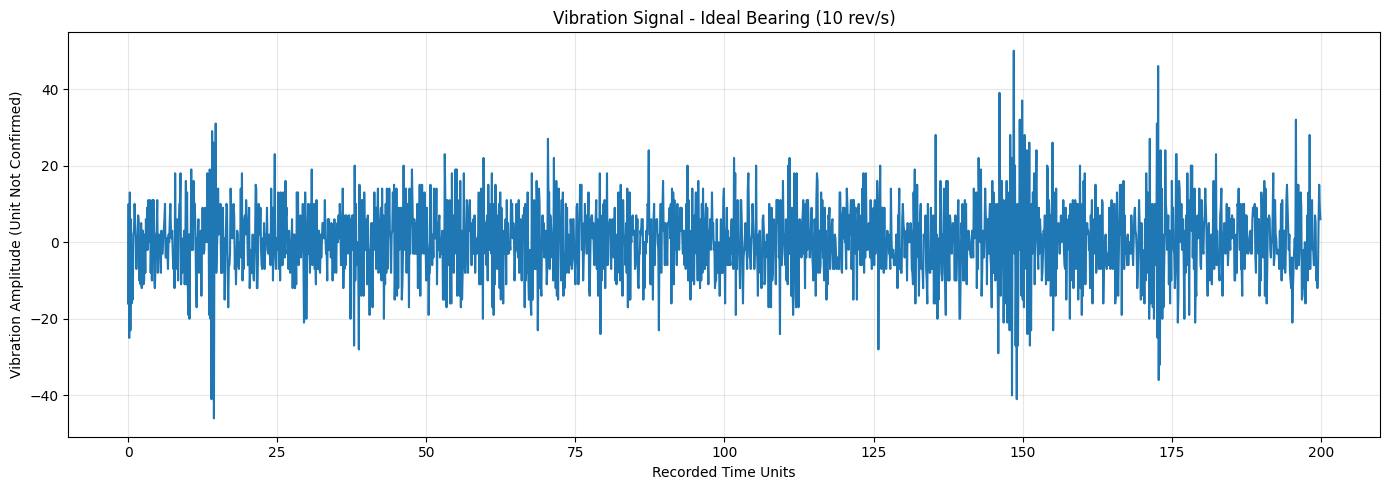

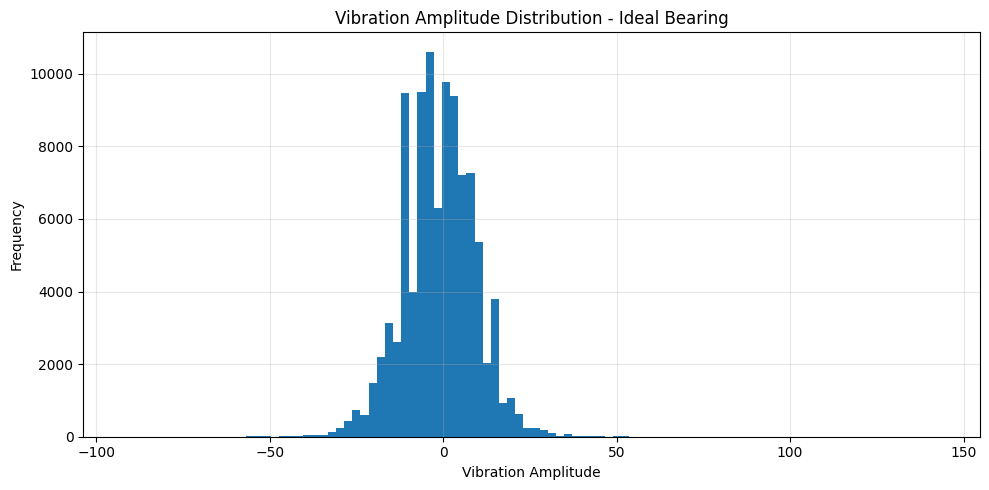

In [8]:
import matplotlib.pyplot as plt
import numpy as np

# Extract columns
time = df.iloc[:, 0]
vibration = df.iloc[:, 1]

# Plot first 2000 samples
plt.figure(figsize=(14, 5))

plt.plot(time.iloc[:2000], vibration.iloc[:2000])

plt.title("Vibration Signal - Ideal Bearing (10 rev/s)")
plt.xlabel("Recorded Time Units")
plt.ylabel("Vibration Amplitude (Unit Not Confirmed)")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# Plot signal distribution using a sample
sample = vibration.sample(
    n=min(100000, len(vibration)),
    random_state=42
)

plt.figure(figsize=(10, 5))

plt.hist(sample, bins=100)

plt.title("Vibration Amplitude Distribution - Ideal Bearing")
plt.xlabel("Vibration Amplitude")
plt.ylabel("Frequency")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

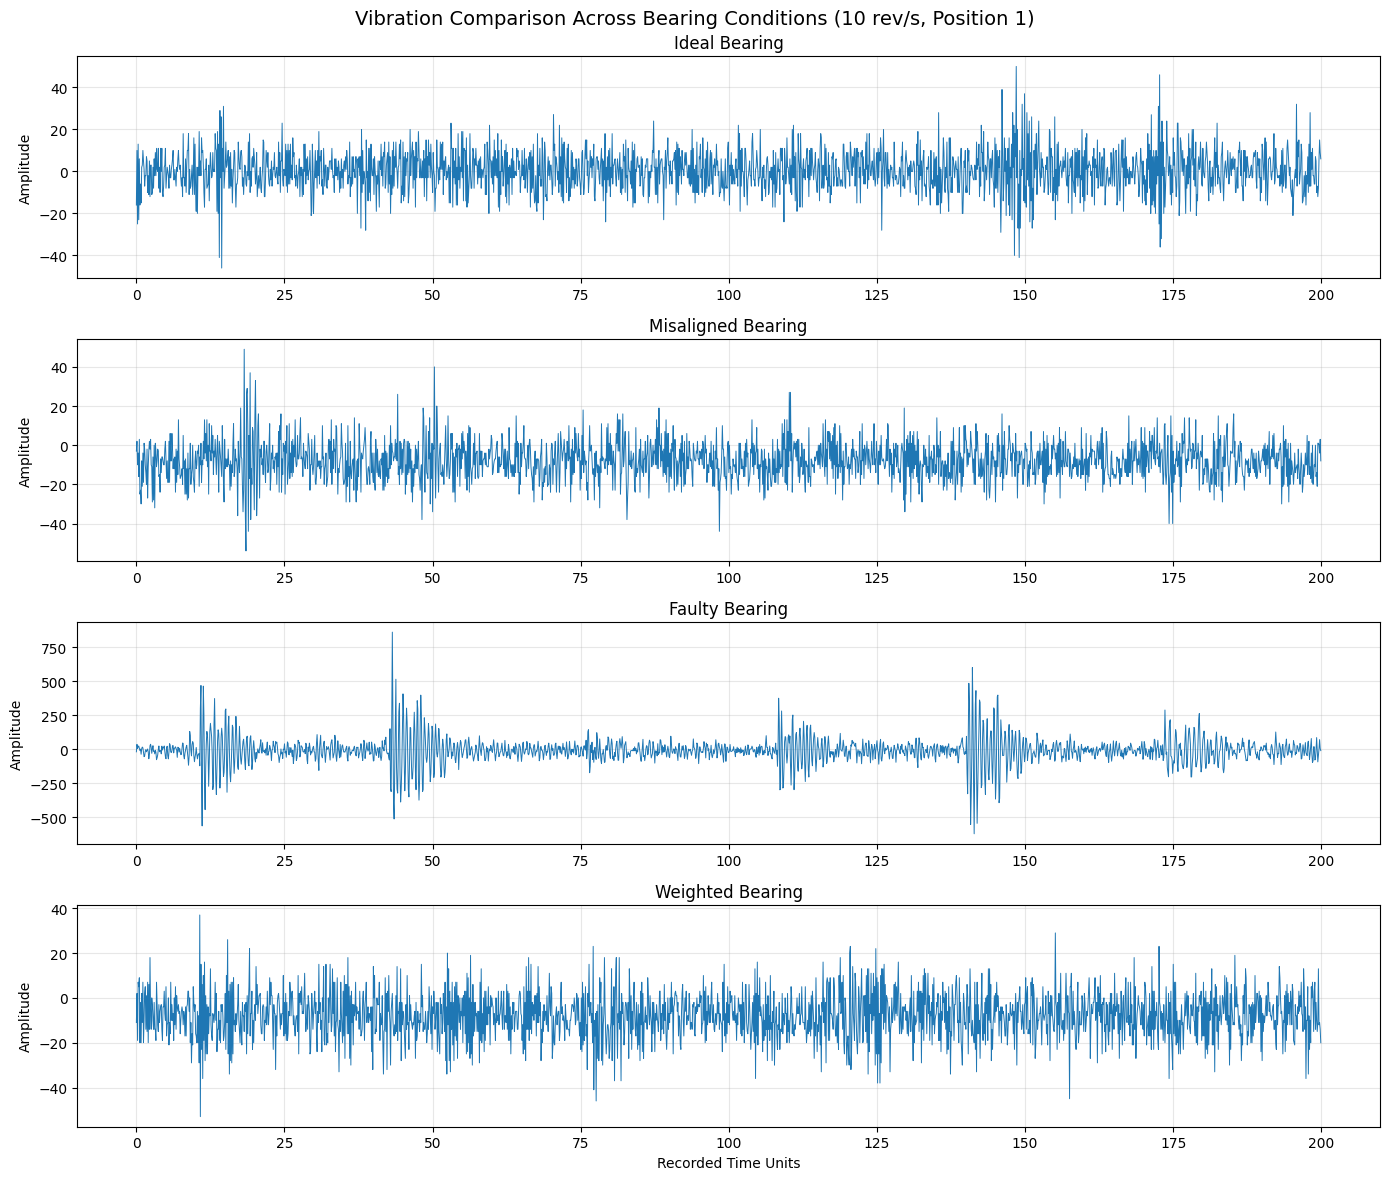

In [9]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# Select recordings at 10 rev/s, sensor position 1
conditions = {
    "Ideal": "ideal10rev.csv",
    "Misaligned": "misaligned10rev.csv",
    "Faulty": "faulty10rev.csv",
    "Weighted": "idealweight10rev.csv"
}

fig, axes = plt.subplots(4, 1, figsize=(14, 12))

for ax, (condition, filename) in zip(axes, conditions.items()):

    file_path = next(
        f for f in csv_files
        if os.path.basename(f) == filename
    )

    data = pd.read_csv(file_path, sep=";", header=None)

    time = data.iloc[:2000, 0]
    vibration = data.iloc[:2000, 1]

    ax.plot(time, vibration, linewidth=0.7)
    ax.set_title(f"{condition} Bearing")
    ax.set_ylabel("Amplitude")
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Recorded Time Units")

plt.suptitle(
    "Vibration Comparison Across Bearing Conditions (10 rev/s, Position 1)",
    fontsize=14
)

plt.tight_layout()
plt.show()

In [10]:
import os
import numpy as np
import pandas as pd
from scipy.stats import kurtosis

WINDOW_SIZE = 1000
feature_rows = []

for file_path in sorted(csv_files):

    filename = os.path.basename(file_path).lower()

    # Identify bearing condition
    if "idealweight" in filename:
        condition = "Weighted"
    elif "misaligned" in filename:
        condition = "Misaligned"
    elif "faulty" in filename:
        condition = "Faulty"
    else:
        condition = "Ideal"

    # Identify speed and sensor position
    speed = int(filename.split("rev")[0][-2:]) if False else None

    import re
    speed = int(re.search(r"(\d+)rev", filename).group(1))
    position = 2 if filename.startswith("2") else 1

    data = pd.read_csv(file_path, sep=";", header=None)

    signal = data.iloc[:, 1].to_numpy(dtype=np.float64)

    # Keep only complete windows
    usable_length = (len(signal) // WINDOW_SIZE) * WINDOW_SIZE

    windows = signal[:usable_length].reshape(-1, WINDOW_SIZE)

    means = np.mean(windows, axis=1)
    stds = np.std(windows, axis=1)
    rms = np.sqrt(np.mean(windows**2, axis=1))
    peak_to_peak = np.ptp(windows, axis=1)
    kurt = kurtosis(windows, axis=1, fisher=False)

    peak = np.max(np.abs(windows), axis=1)
    crest_factor = peak / np.maximum(rms, 1e-10)

    for i in range(len(windows)):
        feature_rows.append({
            "condition": condition,
            "speed": speed,
            "position": position,
            "window": i,
            "mean": means[i],
            "std": stds[i],
            "rms": rms[i],
            "peak_to_peak": peak_to_peak[i],
            "kurtosis": kurt[i],
            "crest_factor": crest_factor[i]
        })

features_df = pd.DataFrame(feature_rows)

print("Feature extraction completed!")
print("Total windows:", len(features_df))

display(features_df.head())

print("\nFeature dataset shape:", features_df.shape)

Feature extraction completed!
Total windows: 144000


,condition,speed,position,window,mean,std,rms,peak_to_peak,kurtosis,crest_factor
0,Faulty,10,2,0,-9.592,102.329163,102.777741,1249.0,12.269858,6.499462
1,Faulty,10,2,1,-9.891,76.680487,77.315775,1022.0,14.671248,7.695713
2,Faulty,10,2,2,-9.708,121.195391,121.583584,1792.0,19.426284,8.537337
3,Faulty,10,2,3,-9.562,126.037622,126.399818,1853.0,19.161592,8.037986
4,Faulty,10,2,4,-9.762,142.450417,142.784516,2218.0,21.473224,8.250194



Feature dataset shape: (144000, 10)


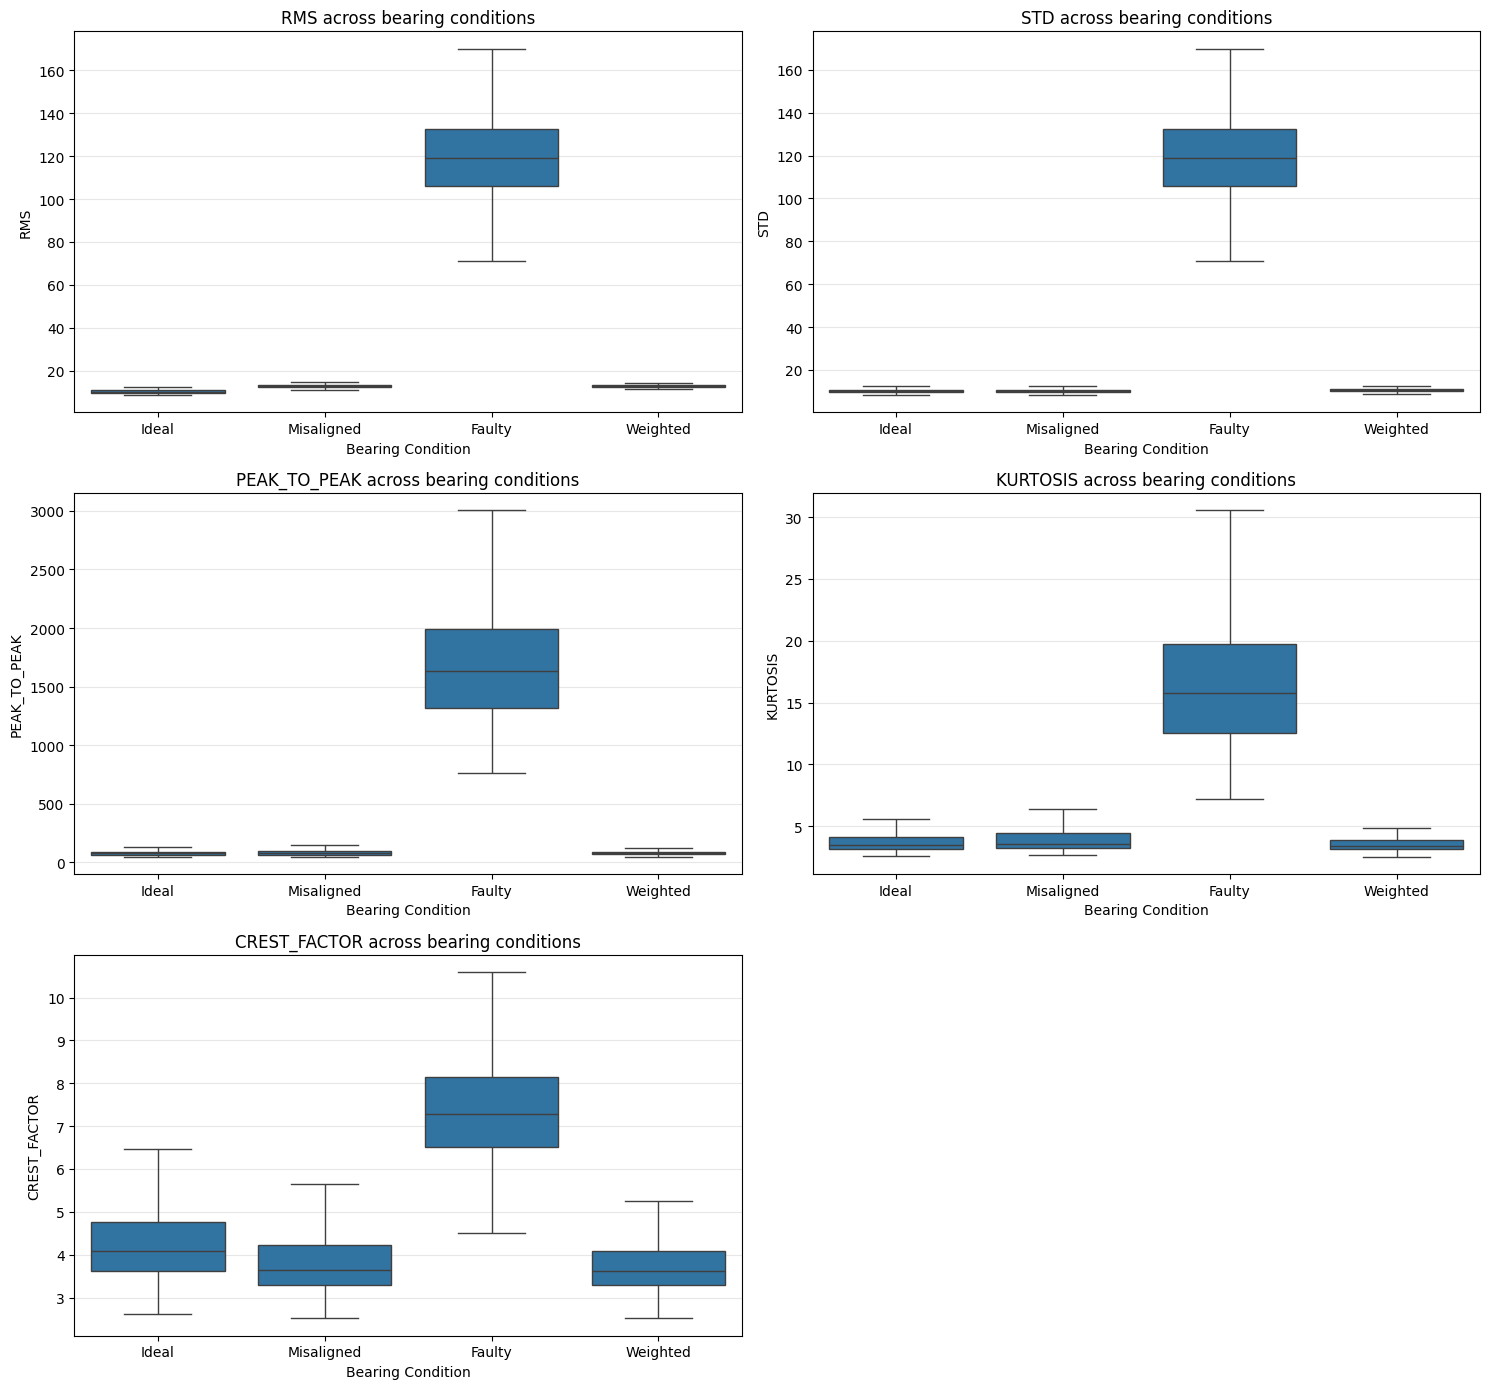

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# Keep speed and sensor position constant
comparison_df = features_df[
    (features_df["speed"] == 10) &
    (features_df["position"] == 1)
]

features_to_plot = [
    "rms",
    "std",
    "peak_to_peak",
    "kurtosis",
    "crest_factor"
]

fig, axes = plt.subplots(3, 2, figsize=(15, 14))

for ax, feature in zip(axes.flat, features_to_plot):

    sns.boxplot(
        data=comparison_df,
        x="condition",
        y=feature,
        order=["Ideal", "Misaligned", "Faulty", "Weighted"],
        showfliers=False,
        ax=ax
    )

    ax.set_title(f"{feature.upper()} across bearing conditions")
    ax.set_xlabel("Bearing Condition")
    ax.set_ylabel(feature.upper())
    ax.grid(axis="y", alpha=0.3)

axes.flat[-1].axis("off")

plt.tight_layout()
plt.show()

In [12]:
# Summarize features for each recording combination

feature_summary = (
    features_df
    .groupby(["condition", "speed", "position"])
    [["rms", "std", "peak_to_peak", "kurtosis", "crest_factor"]]
    .median()
    .reset_index()
)

# Display all 24 combinations
feature_summary = feature_summary.sort_values(
    ["condition", "speed", "position"]
).reset_index(drop=True)

display(feature_summary)

print("Number of recording combinations:", len(feature_summary))

,condition,speed,position,rms,std,peak_to_peak,kurtosis,crest_factor
0,Faulty,10,1,119.187994,118.835885,1635.5,15.798751,7.290150
1,Faulty,10,2,121.570296,121.209641,1737.0,17.158132,7.600225
2,Faulty,20,1,422.127655,421.984079,4981.0,10.369983,6.320384
3,Faulty,20,2,437.064792,436.914036,5248.0,10.513842,6.307516
4,Faulty,30,1,1193.932291,1193.870744,12022.0,7.920840,5.284530
5,Faulty,30,2,1215.907885,1215.868737,12384.0,8.065047,5.336014
6,Ideal,10,1,10.230469,10.114986,77.0,3.468741,4.087983
7,Ideal,10,2,13.499278,9.871277,77.0,3.571567,3.487620
8,Ideal,20,1,31.828611,31.500400,231.0,3.301109,3.953666
9,Ideal,20,2,30.573346,28.829701,238.0,3.648545,4.320361


Number of recording combinations: 24


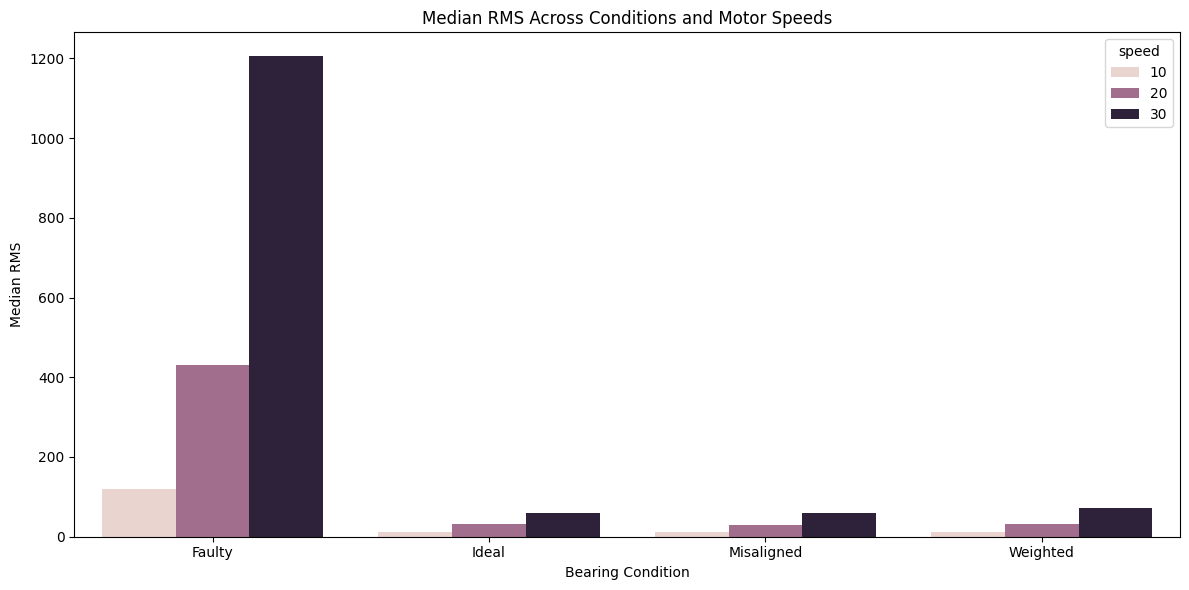

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

sns.barplot(
    data=feature_summary,
    x="condition",
    y="rms",
    hue="speed",
    errorbar=None
)

plt.title("Median RMS Across Conditions and Motor Speeds")
plt.ylabel("Median RMS")
plt.xlabel("Bearing Condition")

plt.tight_layout()
plt.show()

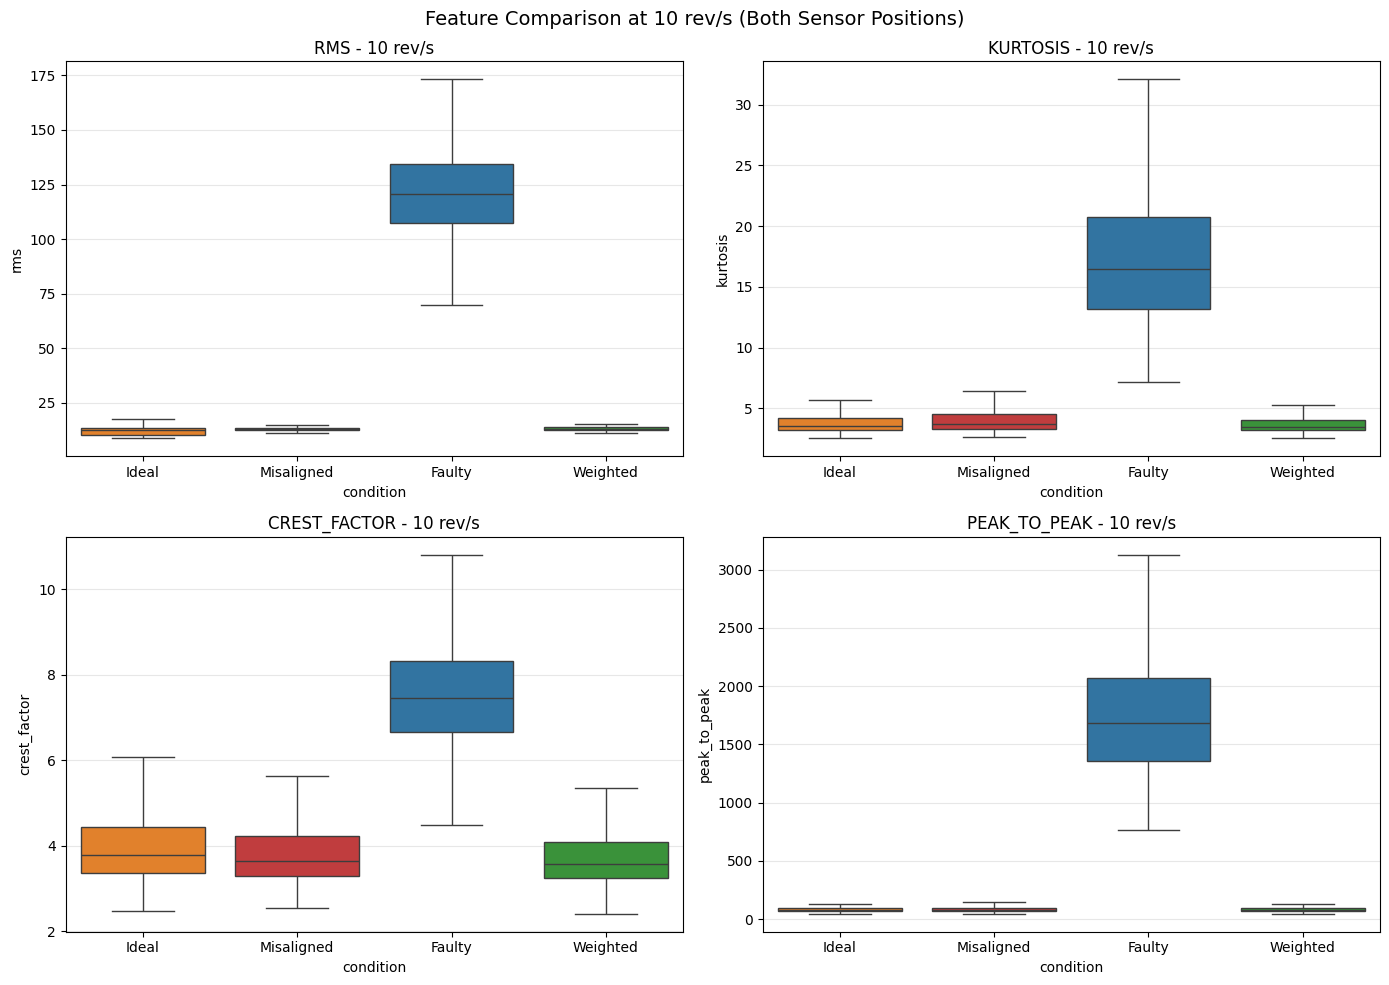

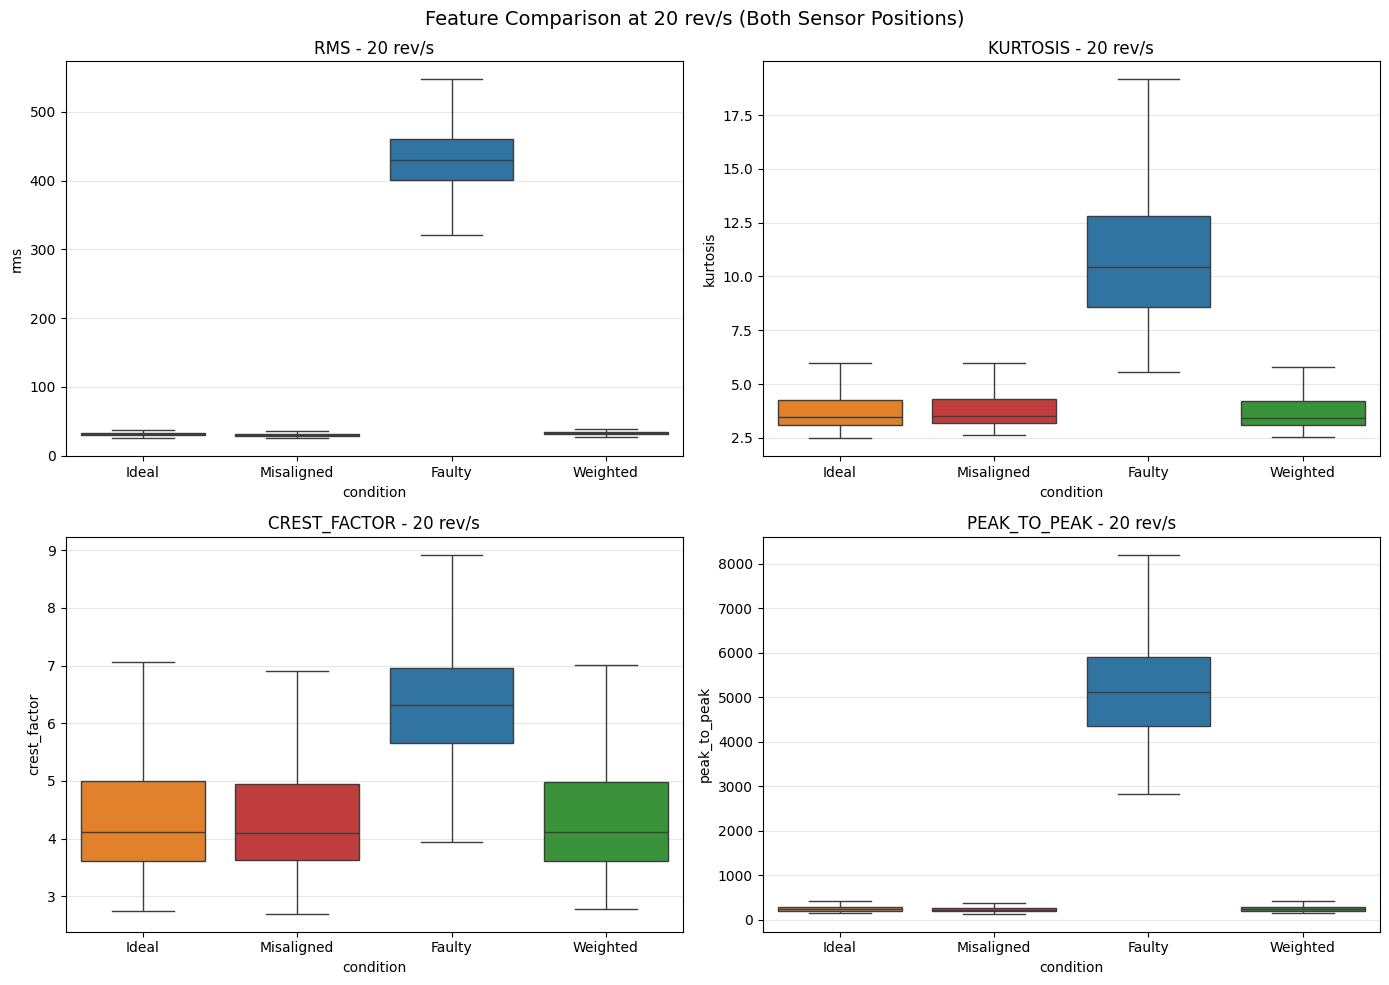

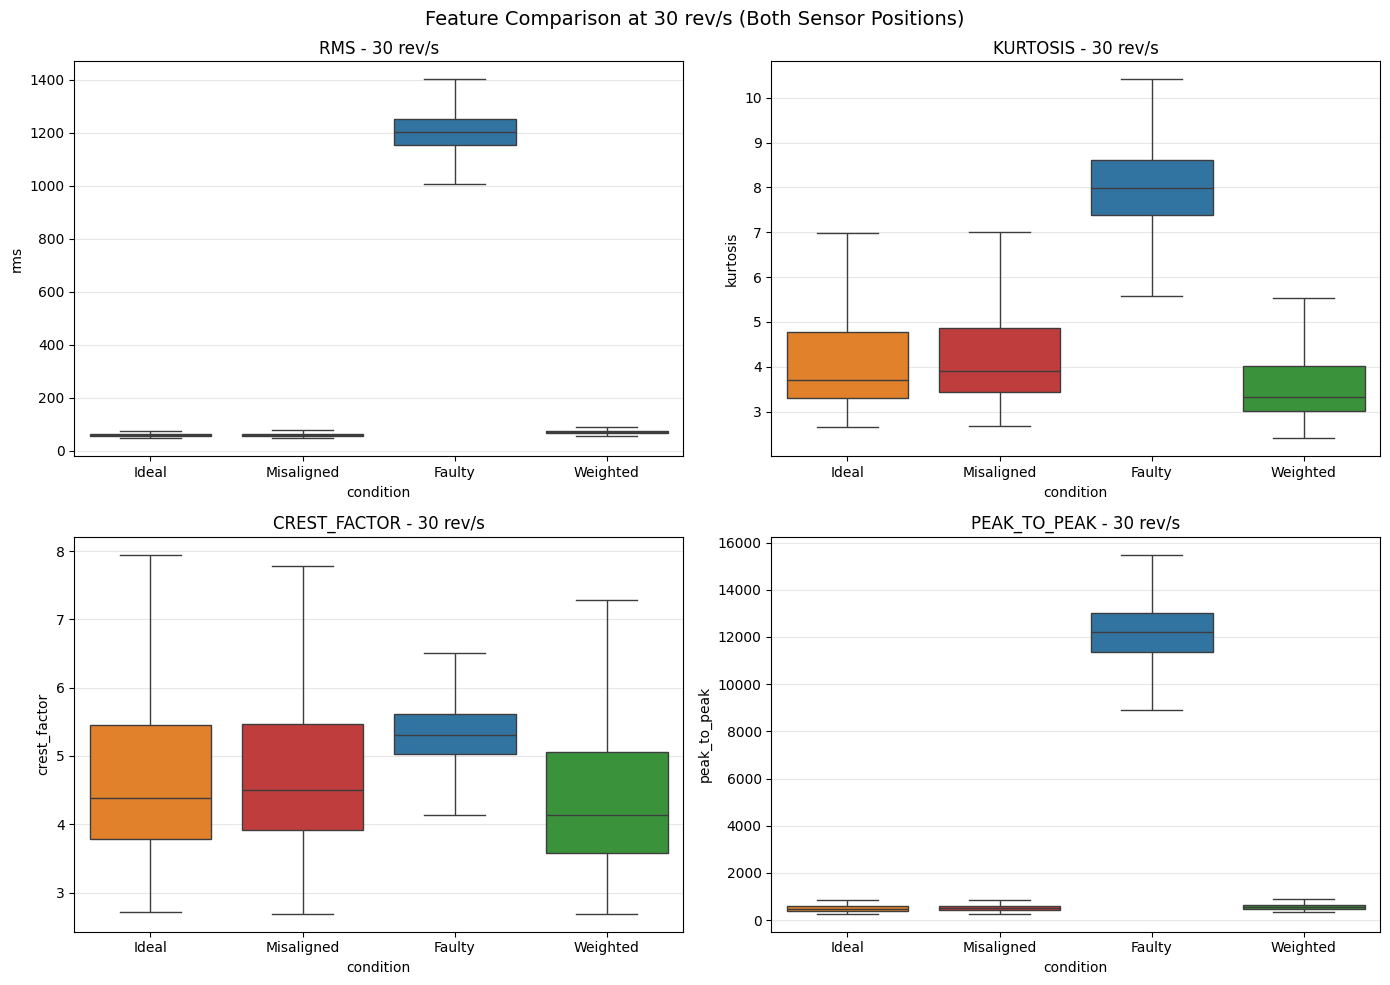

In [14]:
import seaborn as sns
import matplotlib.pyplot as plt

features_to_compare = [
    "rms",
    "kurtosis",
    "crest_factor",
    "peak_to_peak"
]

for speed in [10, 20, 30]:

    speed_df = features_df[
        features_df["speed"] == speed
    ]

    fig, axes = plt.subplots(2, 2, figsize=(14, 10))

    for ax, feature in zip(axes.flat, features_to_compare):

        sns.boxplot(
            data=speed_df,
            x="condition",
            y=feature,
            order=["Ideal", "Misaligned", "Faulty", "Weighted"],
            hue="condition",
            legend=False,
            showfliers=False,
            ax=ax
        )

        ax.set_title(f"{feature.upper()} - {speed} rev/s")
        ax.grid(axis="y", alpha=0.3)

    plt.suptitle(
        f"Feature Comparison at {speed} rev/s (Both Sensor Positions)",
        fontsize=14
    )

    plt.tight_layout()
    plt.show()

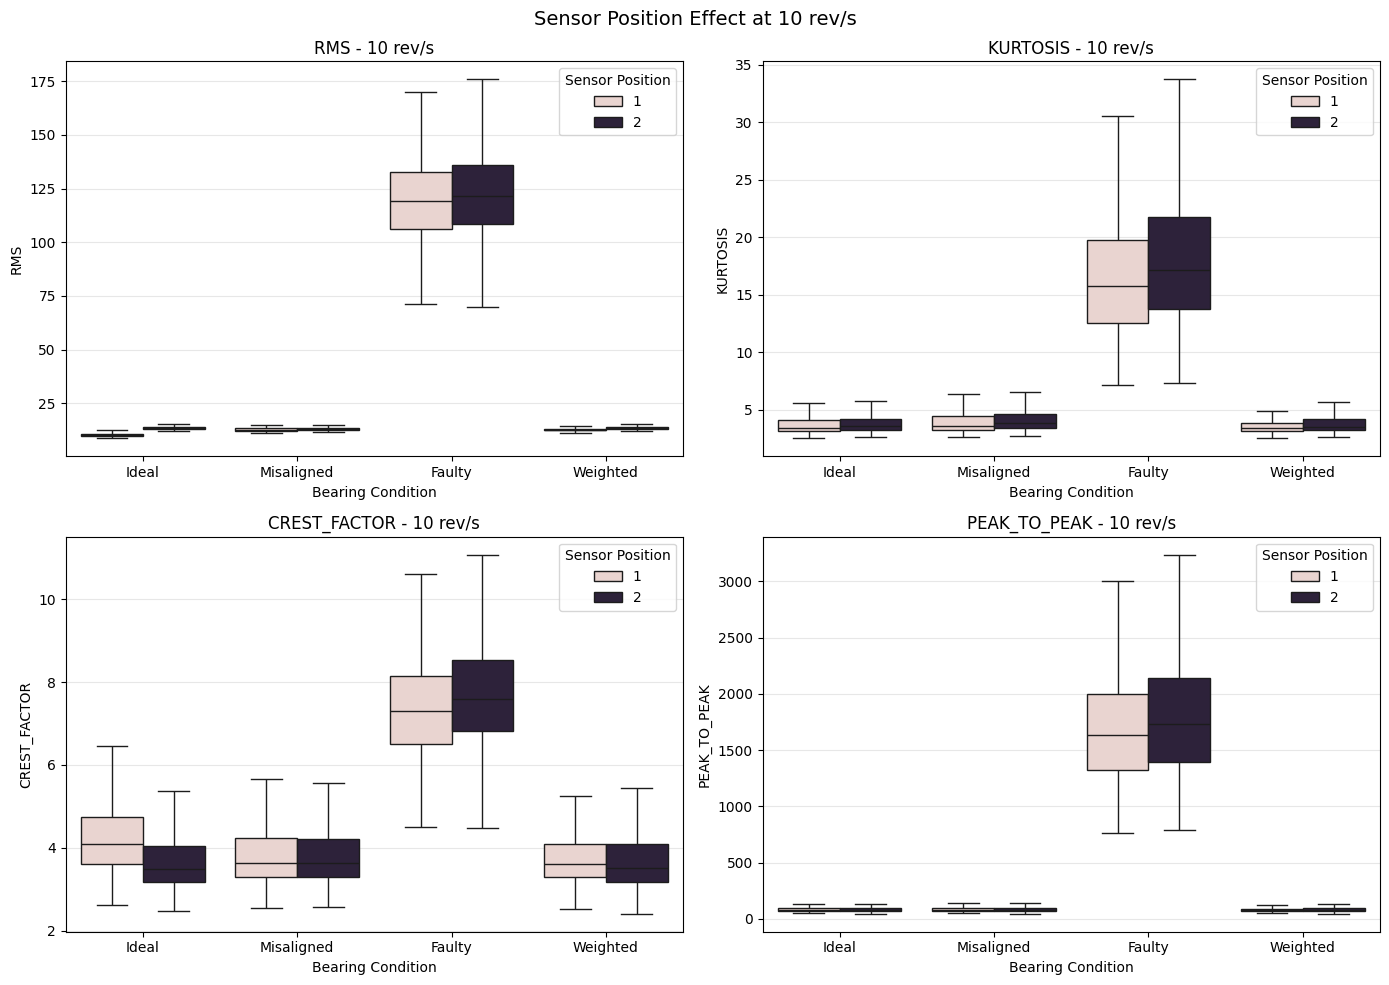

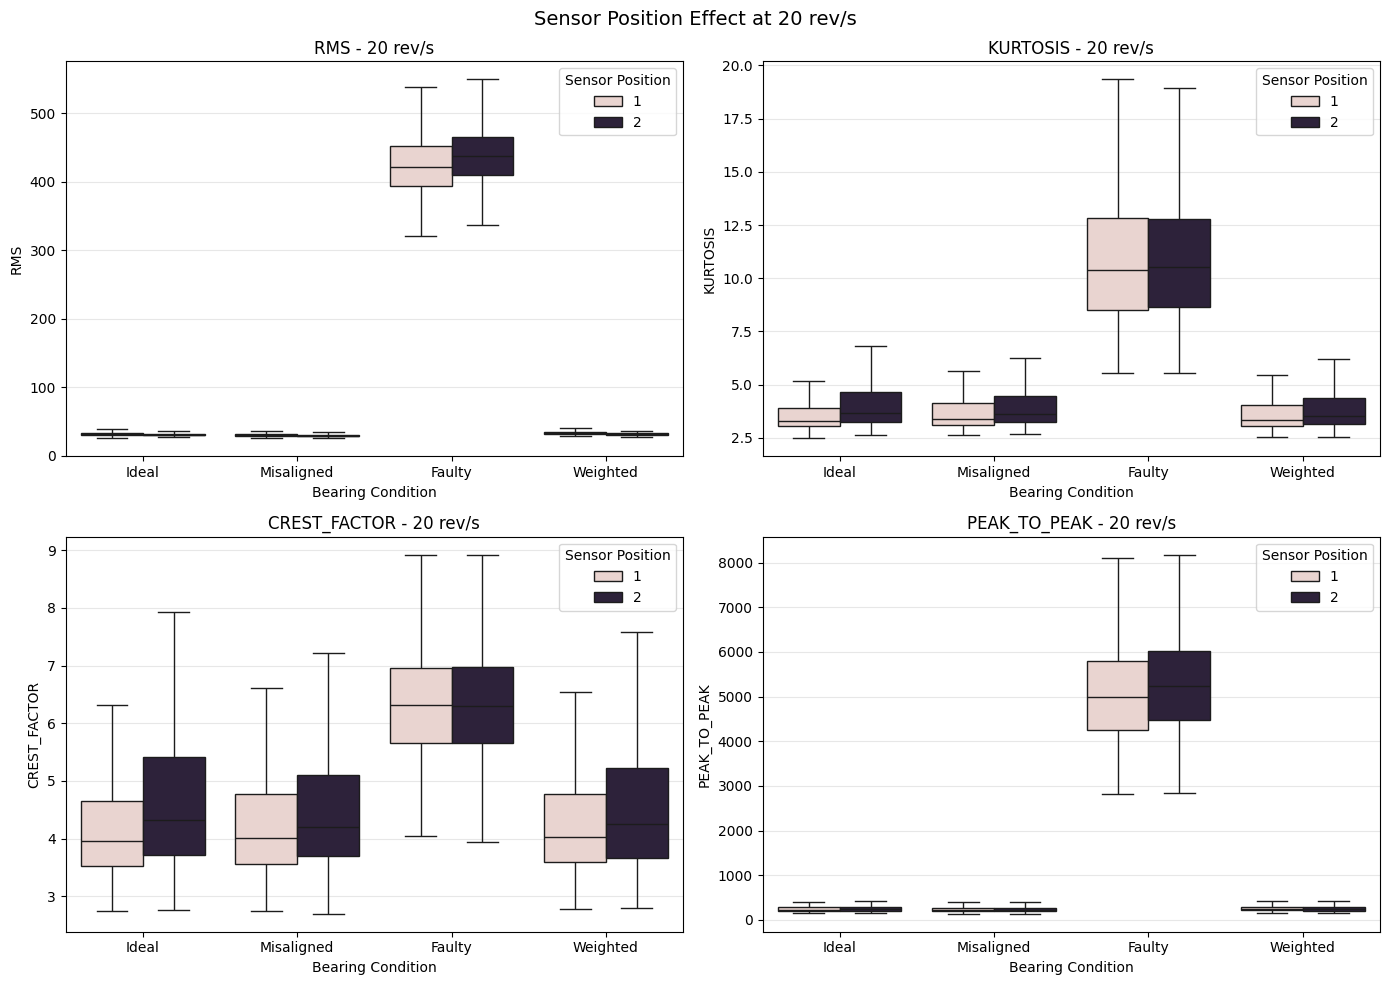

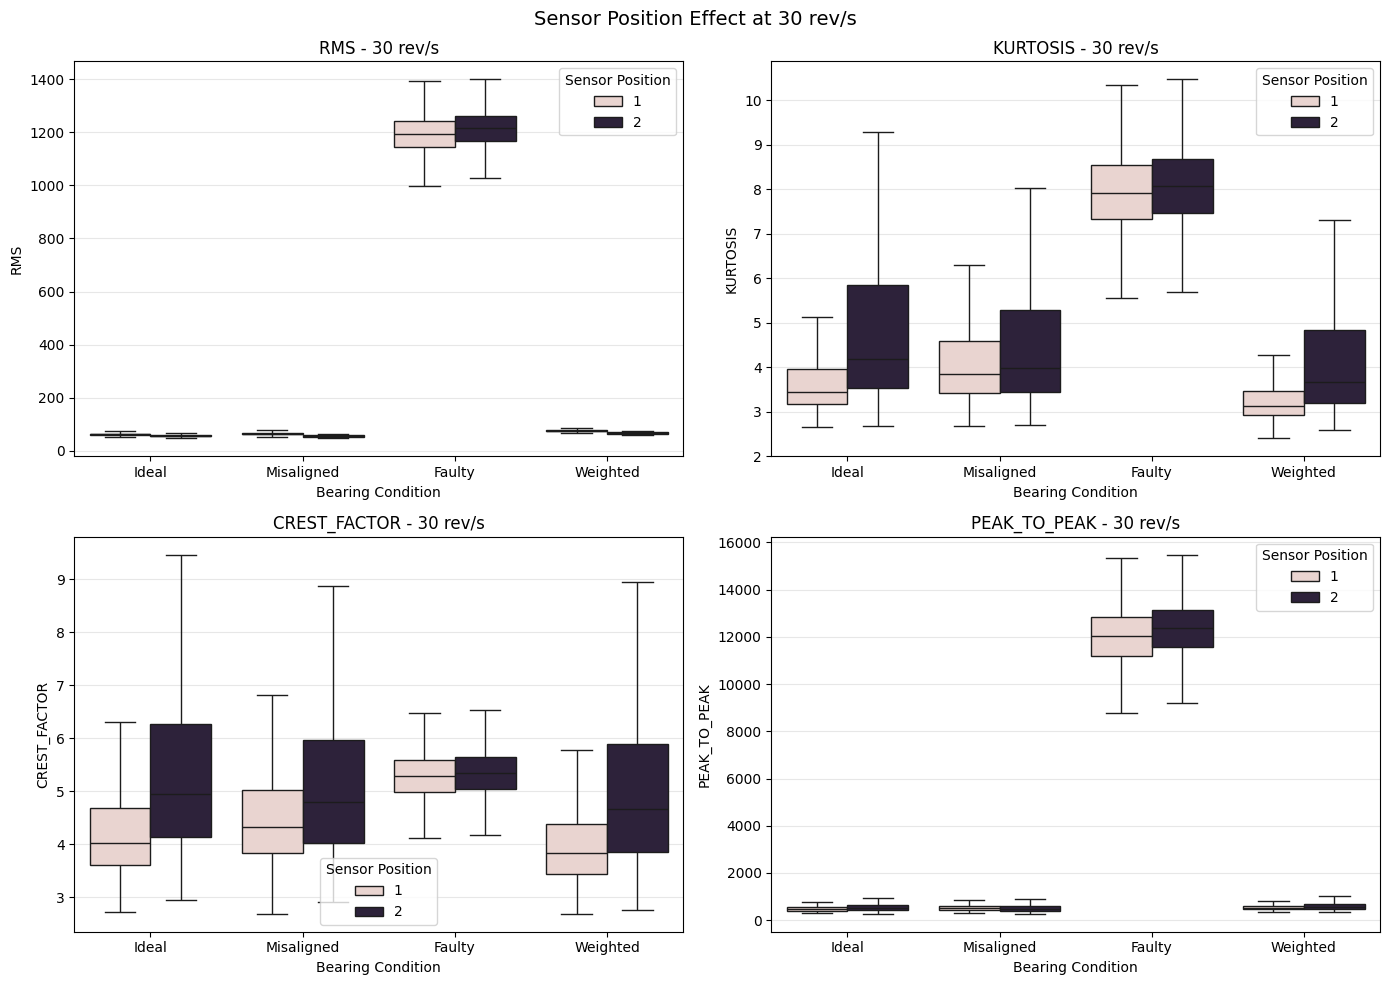

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt

features_to_compare = [
    "rms",
    "kurtosis",
    "crest_factor",
    "peak_to_peak"
]

for speed in [10, 20, 30]:

    speed_df = features_df[
        features_df["speed"] == speed
    ]

    fig, axes = plt.subplots(2, 2, figsize=(14, 10))

    for ax, feature in zip(axes.flat, features_to_compare):

        sns.boxplot(
            data=speed_df,
            x="condition",
            y=feature,
            hue="position",
            order=["Ideal", "Misaligned", "Faulty", "Weighted"],
            showfliers=False,
            ax=ax
        )

        ax.set_title(f"{feature.upper()} - {speed} rev/s")
        ax.set_xlabel("Bearing Condition")
        ax.set_ylabel(feature.upper())
        ax.legend(title="Sensor Position")
        ax.grid(axis="y", alpha=0.3)

    plt.suptitle(
        f"Sensor Position Effect at {speed} rev/s",
        fontsize=14
    )

    plt.tight_layout()
    plt.show()

In [16]:
import pandas as pd
import numpy as np

features = [
    "rms",
    "std",
    "peak_to_peak",
    "kurtosis",
    "crest_factor"
]

position_summary = (
    features_df
    .groupby(["condition", "speed", "position"])[features]
    .median()
    .reset_index()
)

position_1 = (
    position_summary[position_summary["position"] == 1]
    .drop(columns="position")
    .set_index(["condition", "speed"])
)

position_2 = (
    position_summary[position_summary["position"] == 2]
    .drop(columns="position")
    .set_index(["condition", "speed"])
)

position_difference = (
    (position_2 - position_1) /
    position_1.abs().replace(0, np.nan)
) * 100

position_difference = position_difference.reset_index()

print("Percentage difference: Position 2 vs Position 1")
display(position_difference.round(2))

Percentage difference: Position 2 vs Position 1


,condition,speed,rms,std,peak_to_peak,kurtosis,crest_factor
0,Faulty,10,2.00,2.00,6.21,8.60,4.25
1,Faulty,20,3.54,3.54,5.36,1.39,-0.20
2,Faulty,30,1.84,1.84,3.01,1.82,0.97
3,Ideal,10,31.95,-2.41,0.00,2.96,-14.69
4,Ideal,20,-3.94,-8.48,3.03,10.52,9.27
5,Ideal,30,-9.44,-10.81,8.99,21.82,23.22
6,Misaligned,10,2.25,-4.07,2.56,7.15,-0.23
7,Misaligned,20,-3.86,-5.30,0.90,5.82,4.92
8,Misaligned,30,-13.85,-14.30,-7.34,3.30,10.78
9,Weighted,10,5.56,-4.64,1.30,4.72,-2.79


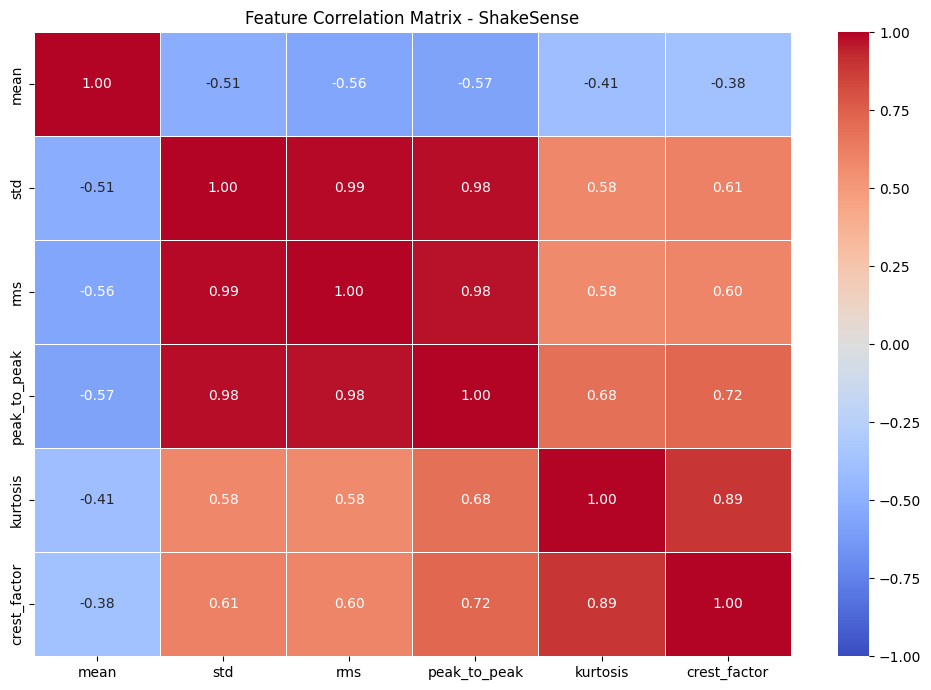

In [17]:
import seaborn as sns
import matplotlib.pyplot as plt

features = [
    "mean",
    "std",
    "rms",
    "peak_to_peak",
    "kurtosis",
    "crest_factor"
]

correlation_matrix = features_df[features].corr(method="spearman")

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title("Feature Correlation Matrix - ShakeSense")
plt.tight_layout()
plt.show()

In [18]:
# Assign a unique ID to each original recording

features_df["recording_id"] = (
    features_df["condition"].astype(str) + "_" +
    features_df["speed"].astype(str) + "rev_" +
    features_df["position"].astype(str)
)

print("Total windows:", len(features_df))
print("Unique recordings:", features_df["recording_id"].nunique())

print("\nRecording distribution:")

recording_summary = (
    features_df
    .groupby(["recording_id", "condition", "speed", "position"])
    .size()
    .reset_index(name="windows")
)

display(recording_summary)

Total windows: 144000
Unique recordings: 24

Recording distribution:


,recording_id,condition,speed,position,windows
0,Faulty_10rev_1,Faulty,10,1,6000
1,Faulty_10rev_2,Faulty,10,2,6000
2,Faulty_20rev_1,Faulty,20,1,6000
3,Faulty_20rev_2,Faulty,20,2,6000
4,Faulty_30rev_1,Faulty,30,1,6000
5,Faulty_30rev_2,Faulty,30,2,6000
6,Ideal_10rev_1,Ideal,10,1,6000
7,Ideal_10rev_2,Ideal,10,2,6000
8,Ideal_20rev_1,Ideal,20,1,6000
9,Ideal_20rev_2,Ideal,20,2,6000


In [19]:
# Split by complete original recordings

test_recordings = [
    f"{condition}_30rev_2"
    for condition in ["Ideal", "Misaligned", "Faulty", "Weighted"]
]

validation_recordings = [
    f"{condition}_20rev_1"
    for condition in ["Ideal", "Misaligned", "Faulty", "Weighted"]
]

train_recordings = [
    recording
    for recording in features_df["recording_id"].unique()
    if recording not in test_recordings + validation_recordings
]

# Create datasets
train_df = features_df[
    features_df["recording_id"].isin(train_recordings)
].copy()

val_df = features_df[
    features_df["recording_id"].isin(validation_recordings)
].copy()

test_df = features_df[
    features_df["recording_id"].isin(test_recordings)
].copy()

# Verify split sizes
print("TRAINING")
print("Windows:", len(train_df))
print("Recordings:", train_df["recording_id"].nunique())

print("\nVALIDATION")
print("Windows:", len(val_df))
print("Recordings:", val_df["recording_id"].nunique())

print("\nTESTING")
print("Windows:", len(test_df))
print("Recordings:", test_df["recording_id"].nunique())

# Check class distribution
print("\nClass distribution:")
for name, data in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(f"\n{name}:")
    display(data.groupby("condition")["recording_id"].nunique())

# Check for recording leakage
assert set(train_recordings).isdisjoint(validation_recordings)
assert set(train_recordings).isdisjoint(test_recordings)
assert set(validation_recordings).isdisjoint(test_recordings)

print("\nNo recording overlap detected!")

TRAINING
Windows: 96000
Recordings: 16

VALIDATION
Windows: 24000
Recordings: 4

TESTING
Windows: 24000
Recordings: 4

Class distribution:

Train:


,recording_id
condition,
Faulty,4
Ideal,4
Misaligned,4
Weighted,4



Validation:


,recording_id
condition,
Faulty,1
Ideal,1
Misaligned,1
Weighted,1



Test:


,recording_id
condition,
Faulty,1
Ideal,1
Misaligned,1
Weighted,1



No recording overlap detected!


In [20]:
# Selected vibration features
selected_features = [
    "mean",
    "rms",
    "peak_to_peak",
    "kurtosis",
    "crest_factor"
]

# Separate input features (X) and target labels (y)
X_train = train_df[selected_features].copy()
y_train = train_df["condition"].copy()

X_val = val_df[selected_features].copy()
y_val = val_df["condition"].copy()

X_test = test_df[selected_features].copy()
y_test = test_df["condition"].copy()

# Verify shapes
print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

print("\nFeatures used:", selected_features)
print("\nTarget classes:", sorted(y_train.unique()))

# Check missing and infinite values
print("\nMissing values:", X_train.isna().sum().sum())
print("Infinite values:", np.isinf(X_train.to_numpy()).sum())

Training: (96000, 5) (96000,)
Validation: (24000, 5) (24000,)
Testing: (24000, 5) (24000,)

Features used: ['mean', 'rms', 'peak_to_peak', 'kurtosis', 'crest_factor']

Target classes: ['Faulty', 'Ideal', 'Misaligned', 'Weighted']

Missing values: 0
Infinite values: 0


TRAINING ACCURACY: 0.8568

VALIDATION ACCURACY: 0.8342

VALIDATION CLASSIFICATION REPORT:
              precision    recall  f1-score   support

      Faulty       1.00      1.00      1.00      6000
       Ideal       0.88      1.00      0.94      6000
  Misaligned       0.96      0.49      0.64      6000
    Weighted       0.63      0.85      0.72      6000

    accuracy                           0.83     24000
   macro avg       0.87      0.83      0.83     24000
weighted avg       0.87      0.83      0.83     24000



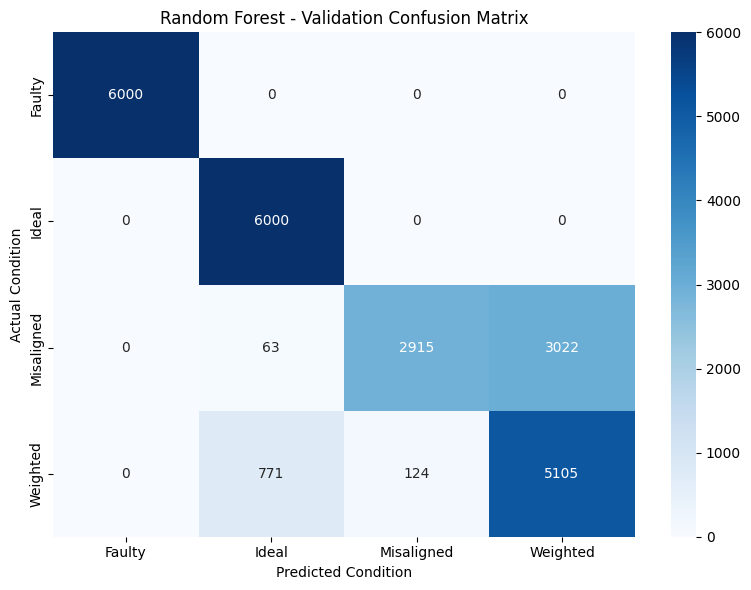

In [21]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
import seaborn as sns
import matplotlib.pyplot as plt

# Initialize baseline Random Forest
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=15,
    min_samples_split=10,
    min_samples_leaf=5,
    max_features="sqrt",
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Train
rf_model.fit(X_train, y_train)

# Predictions
y_train_pred = rf_model.predict(X_train)
y_val_pred = rf_model.predict(X_val)

# Evaluate
print("TRAINING ACCURACY:",
      round(accuracy_score(y_train, y_train_pred), 4))

print("\nVALIDATION ACCURACY:",
      round(accuracy_score(y_val, y_val_pred), 4))

print("\nVALIDATION CLASSIFICATION REPORT:")
print(classification_report(y_val, y_val_pred, zero_division=0))

# Validation confusion matrix
labels = ["Faulty", "Ideal", "Misaligned", "Weighted"]

cm = confusion_matrix(y_val, y_val_pred, labels=labels)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.xlabel("Predicted Condition")
plt.ylabel("Actual Condition")
plt.title("Random Forest - Validation Confusion Matrix")
plt.tight_layout()
plt.show()

Random Forest Feature Importance:


,Feature,Importance
1,rms,0.332530
2,peak_to_peak,0.281522
0,mean,0.227139
3,kurtosis,0.121522
4,crest_factor,0.037287


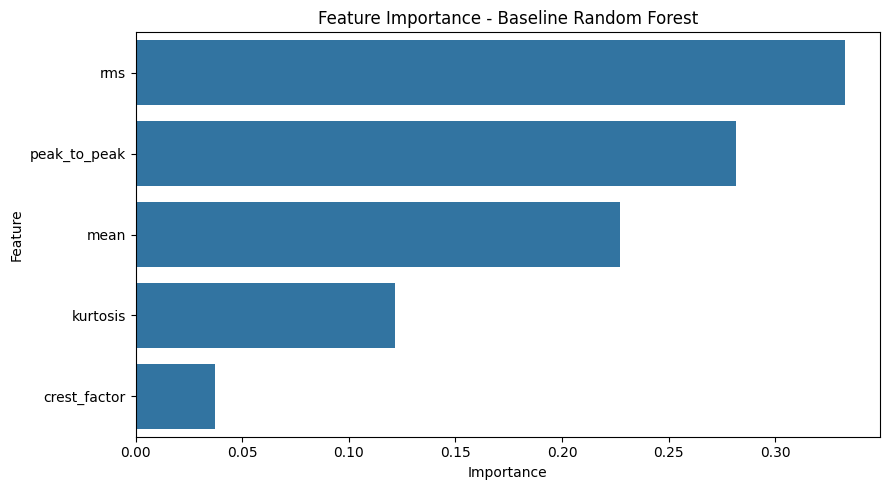

In [22]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

importance_df = pd.DataFrame({
    "Feature": selected_features,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False)

print("Random Forest Feature Importance:")
display(importance_df)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance - Baseline Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

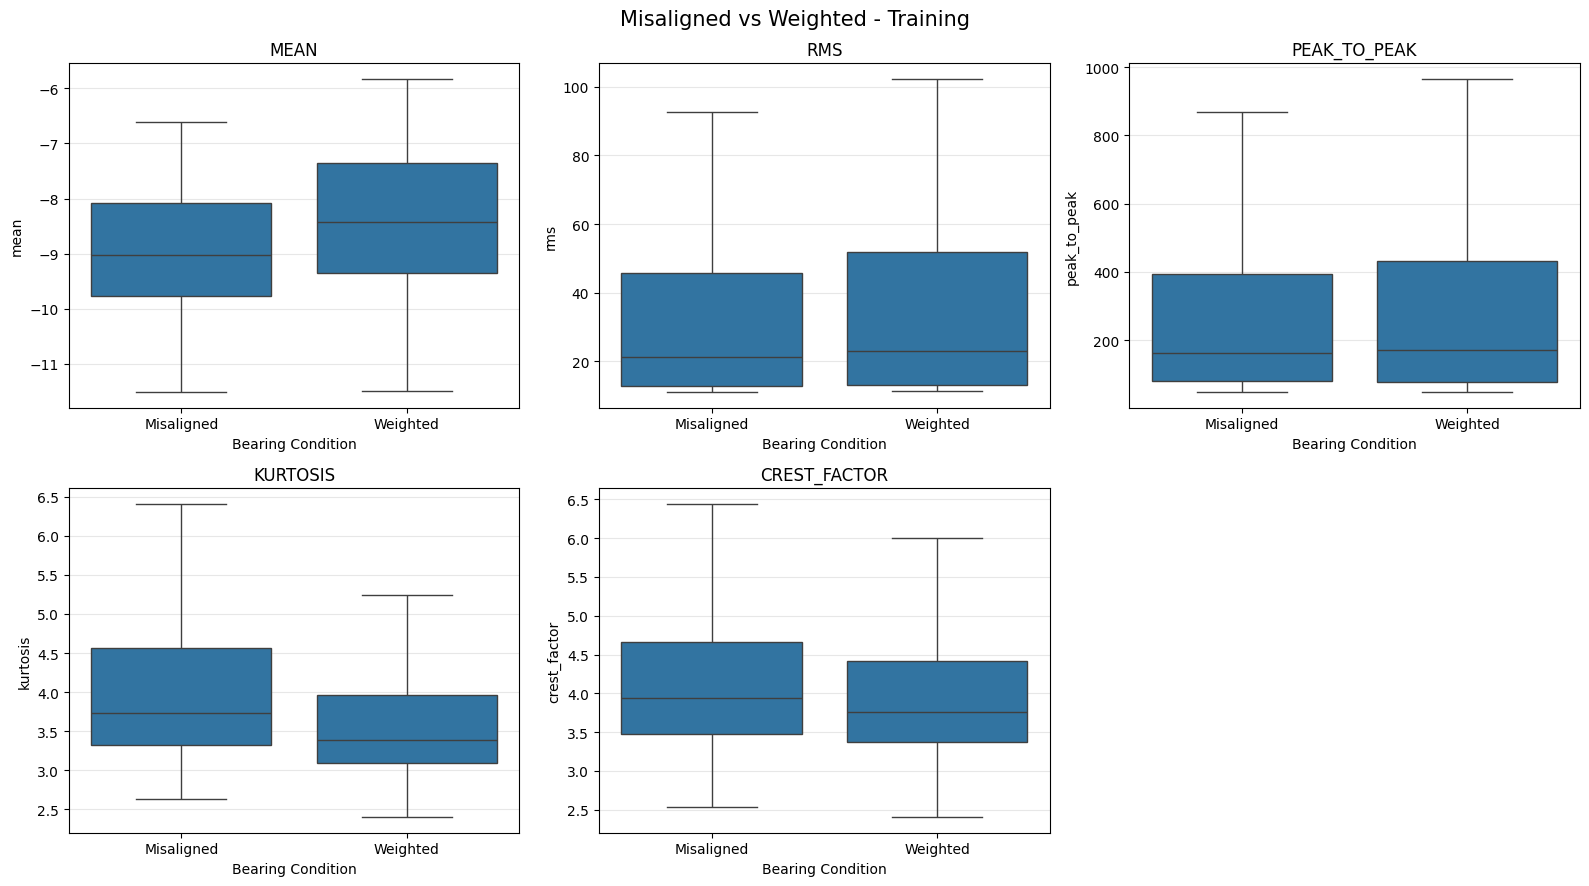

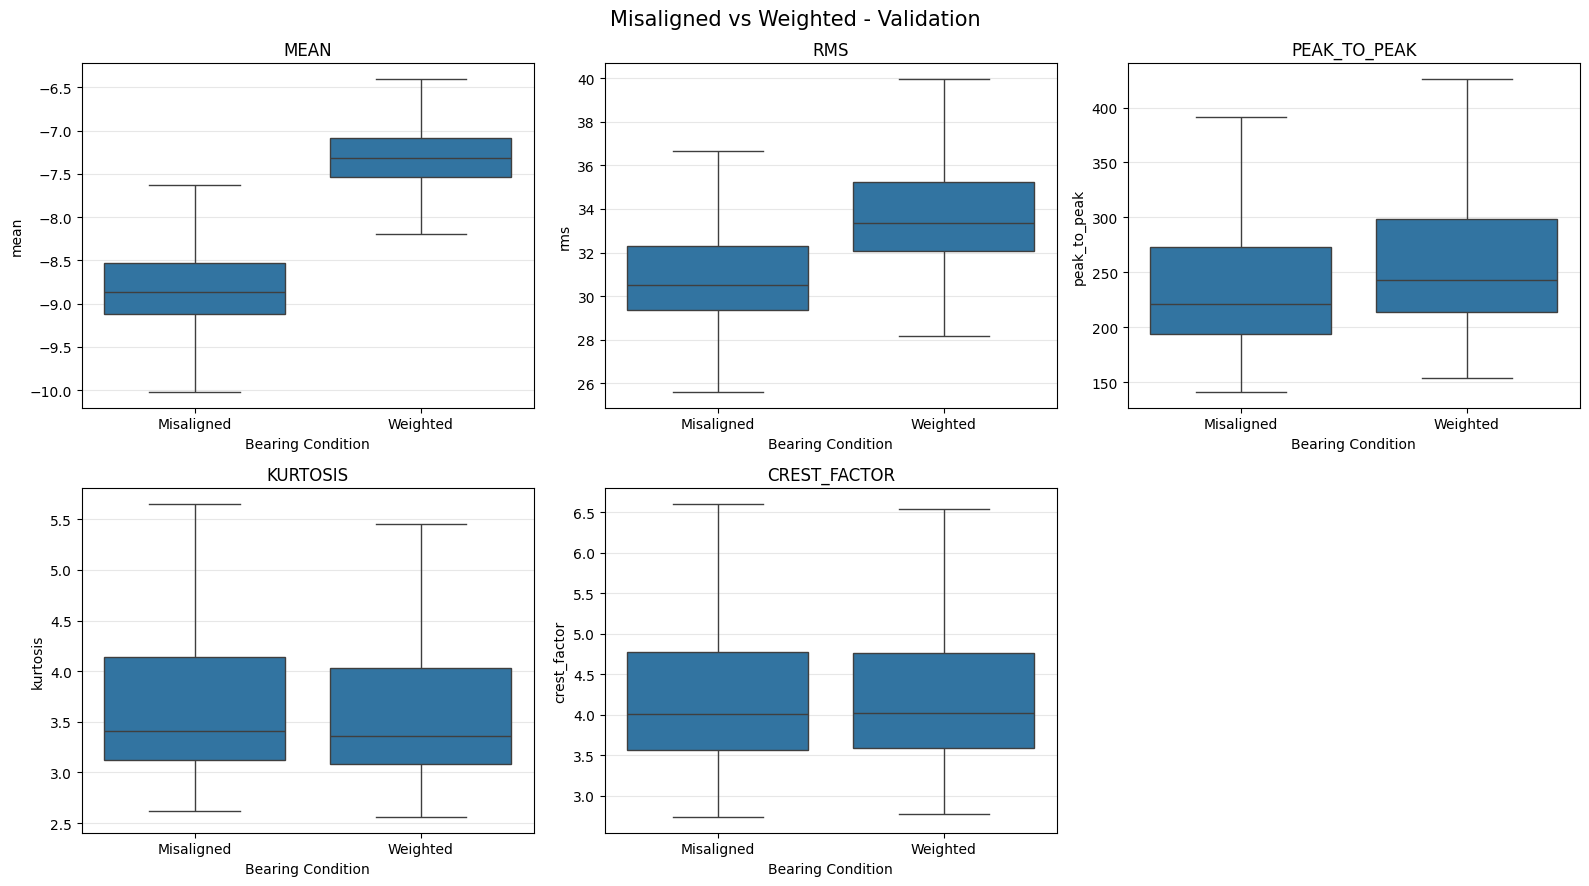

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

features_to_check = [
    "mean",
    "rms",
    "peak_to_peak",
    "kurtosis",
    "crest_factor"
]

conditions_to_check = ["Misaligned", "Weighted"]

for dataset_name, dataset in [
    ("Training", train_df),
    ("Validation", val_df)
]:
    comparison_df = dataset[
        dataset["condition"].isin(conditions_to_check)
    ]

    fig, axes = plt.subplots(2, 3, figsize=(16, 9))
    axes = axes.flatten()

    for ax, feature in zip(axes, features_to_check):
        sns.boxplot(
            data=comparison_df,
            x="condition",
            y=feature,
            order=conditions_to_check,
            showfliers=False,
            ax=ax
        )

        ax.set_title(f"{feature.upper()}")
        ax.set_xlabel("Bearing Condition")
        ax.grid(axis="y", alpha=0.3)

    fig.delaxes(axes[5])

    plt.suptitle(
        f"Misaligned vs Weighted - {dataset_name}",
        fontsize=15
    )
    plt.tight_layout()
    plt.show()

Validation Permutation Importance:


,Feature,Importance,Std
0,mean,0.2963,0.0026
1,rms,0.2729,0.0011
2,peak_to_peak,0.0551,0.0021
3,kurtosis,0.0271,0.0018
4,crest_factor,0.0030,0.0006


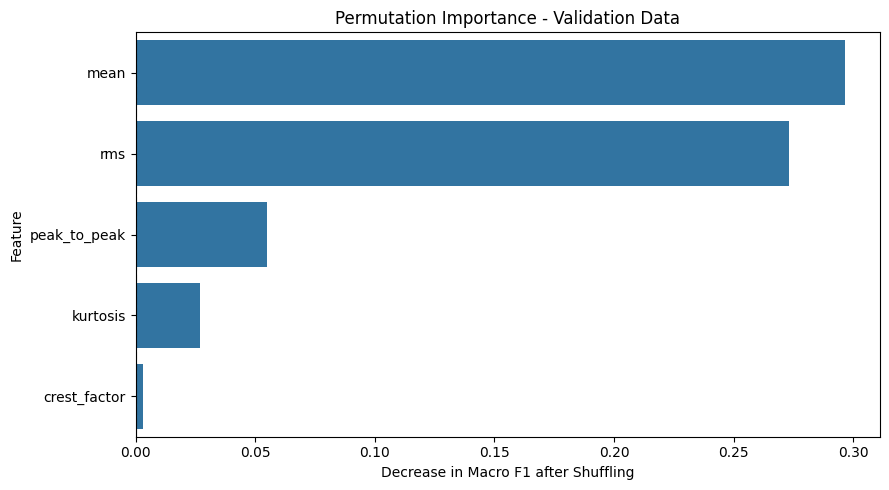

In [24]:
from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Evaluate feature importance on unseen validation data
perm_result = permutation_importance(
    rf_model,
    X_val,
    y_val,
    scoring="f1_macro",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

validation_importance = pd.DataFrame({
    "Feature": selected_features,
    "Importance": perm_result.importances_mean,
    "Std": perm_result.importances_std
}).sort_values("Importance", ascending=False)

print("Validation Permutation Importance:")
display(validation_importance.round(4))

plt.figure(figsize=(9, 5))

sns.barplot(
    data=validation_importance,
    x="Importance",
    y="Feature"
)

plt.axvline(0, linestyle="--", color="black", alpha=0.6)
plt.title("Permutation Importance - Validation Data")
plt.xlabel("Decrease in Macro F1 after Shuffling")
plt.tight_layout()
plt.show()

In [25]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

feature_sets = {
    "All 5 features": [
        "mean", "rms", "peak_to_peak",
        "kurtosis", "crest_factor"
    ],

    "Without crest factor": [
        "mean", "rms", "peak_to_peak", "kurtosis"
    ],

    "Amplitude features": [
        "mean", "rms", "peak_to_peak"
    ],

    "Mean + RMS": [
        "mean", "rms"
    ]
}

ablation_results = []

for name, features in feature_sets.items():

    model = RandomForestClassifier(
        n_estimators=200,
        max_depth=15,
        min_samples_split=10,
        min_samples_leaf=5,
        max_features="sqrt",
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train[features], y_train)

    train_pred = model.predict(X_train[features])
    val_pred = model.predict(X_val[features])

    ablation_results.append({
        "Feature Set": name,
        "Training Accuracy": accuracy_score(y_train, train_pred),
        "Validation Accuracy": accuracy_score(y_val, val_pred),
        "Validation Macro F1": f1_score(
            y_val, val_pred, average="macro"
        )
    })

ablation_df = pd.DataFrame(ablation_results)

display(ablation_df.round(4))

,Feature Set,Training Accuracy,Validation Accuracy,Validation Macro F1
0,All 5 features,0.8568,0.8342,0.8257
1,Without crest factor,0.8518,0.8262,0.8168
2,Amplitude features,0.8358,0.8070,0.8003
3,Mean + RMS,0.8143,0.8256,0.8209


In [26]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd
import numpy as np

X = features_df[selected_features]
y = features_df["condition"]
groups = features_df["recording_id"]

sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []

for fold, (train_idx, val_idx) in enumerate(
    sgkf.split(X, y, groups), start=1
):

    X_tr, X_va = X.iloc[train_idx], X.iloc[val_idx]
    y_tr, y_va = y.iloc[train_idx], y.iloc[val_idx]

    model = RandomForestClassifier(
        n_estimators=200,
        max_depth=15,
        min_samples_split=10,
        min_samples_leaf=5,
        max_features="sqrt",
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_tr, y_tr)

    predictions = model.predict(X_va)

    cv_results.append({
        "Fold": fold,
        "Train Recordings": groups.iloc[train_idx].nunique(),
        "Validation Recordings": groups.iloc[val_idx].nunique(),
        "Validation Accuracy": accuracy_score(y_va, predictions),
        "Validation Macro F1": f1_score(
            y_va, predictions, average="macro"
        )
    })

cv_df = pd.DataFrame(cv_results)

display(cv_df.round(4))

print("\nMean CV Accuracy:",
      round(cv_df["Validation Accuracy"].mean(), 4))

print("Mean CV Macro F1:",
      round(cv_df["Validation Macro F1"].mean(), 4))

print("CV Macro F1 Std:",
      round(cv_df["Validation Macro F1"].std(), 4))

,Fold,Train Recordings,Validation Recordings,Validation Accuracy,Validation Macro F1
0,1,19,5,0.4422,0.4168
1,2,19,5,0.4815,0.3386
2,3,19,5,0.2087,0.2573
3,4,20,4,0.3037,0.2962
4,5,19,5,0.3164,0.3210



Mean CV Accuracy: 0.3505
Mean CV Macro F1: 0.326
CV Macro F1 Std: 0.0592


In [27]:
from sklearn.model_selection import StratifiedGroupKFold
import pandas as pd

X = features_df[selected_features]
y = features_df["condition"]
groups = features_df["recording_id"]

sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

for fold, (train_idx, val_idx) in enumerate(
    sgkf.split(X, y, groups), start=1
):

    fold_val = features_df.iloc[val_idx]

    print(f"\n========== FOLD {fold} ==========")

    print("Validation recordings:")
    display(
        fold_val[
            ["recording_id", "condition", "speed", "position"]
        ]
        .drop_duplicates()
        .sort_values(["condition", "speed", "position"])
        .reset_index(drop=True)
    )

    print("\nCondition distribution:")
    display(
        fold_val.groupby("condition")["recording_id"]
        .nunique()
    )


========== FOLD 1 ==========
Validation recordings:


,recording_id,condition,speed,position
0,Faulty_10rev_1,Faulty,10,1
1,Ideal_10rev_1,Ideal,10,1
2,Ideal_30rev_1,Ideal,30,1
3,Misaligned_20rev_2,Misaligned,20,2
4,Weighted_20rev_2,Weighted,20,2



Condition distribution:


,recording_id
condition,
Faulty,1
Ideal,2
Misaligned,1
Weighted,1



========== FOLD 2 ==========
Validation recordings:


,recording_id,condition,speed,position
0,Faulty_10rev_2,Faulty,10,2
1,Faulty_30rev_2,Faulty,30,2
2,Misaligned_10rev_2,Misaligned,10,2
3,Misaligned_30rev_2,Misaligned,30,2
4,Weighted_30rev_1,Weighted,30,1


... (10 outputs left out)


========== FOLD 5 ==========
Validation recordings:


,recording_id,condition,speed,position
0,Faulty_30rev_1,Faulty,30,1
1,Ideal_20rev_2,Ideal,20,2
2,Misaligned_20rev_1,Misaligned,20,1
3,Misaligned_30rev_1,Misaligned,30,1
4,Weighted_10rev_1,Weighted,10,1



Condition distribution:


,recording_id
condition,
Faulty,1
Ideal,1
Misaligned,2
Weighted,1


In [28]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

X = features_df[selected_features]
y = features_df["condition"]

cv_results = []

for speed in [10, 20, 30]:
    for position in [1, 2]:

        # Hold out all four conditions at this speed and position
        val_mask = (
            (features_df["speed"] == speed) &
            (features_df["position"] == position)
        )

        train_mask = ~val_mask

        X_tr = X[train_mask]
        y_tr = y[train_mask]

        X_va = X[val_mask]
        y_va = y[val_mask]

        # Verify recording-level separation
        train_ids = set(features_df.loc[train_mask, "recording_id"])
        val_ids = set(features_df.loc[val_mask, "recording_id"])

        assert train_ids.isdisjoint(val_ids)

        model = RandomForestClassifier(
            n_estimators=200,
            max_depth=15,
            min_samples_split=10,
            min_samples_leaf=5,
            max_features="sqrt",
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        )

        model.fit(X_tr, y_tr)

        predictions = model.predict(X_va)

        cv_results.append({
            "Speed": speed,
            "Position": position,
            "Train Recordings": len(train_ids),
            "Validation Recordings": len(val_ids),
            "Validation Accuracy": accuracy_score(y_va, predictions),
            "Validation Macro F1": f1_score(
                y_va,
                predictions,
                labels=["Faulty", "Ideal", "Misaligned", "Weighted"],
                average="macro",
                zero_division=0
            )
        })

cv_results_df = pd.DataFrame(cv_results)

display(cv_results_df.round(4))

print("\nMean Accuracy:",
      round(cv_results_df["Validation Accuracy"].mean(), 4))

print("Mean Macro F1:",
      round(cv_results_df["Validation Macro F1"].mean(), 4))

print("Macro F1 Standard Deviation:",
      round(cv_results_df["Validation Macro F1"].std(), 4))

,Speed,Position,Train Recordings,Validation Recordings,Validation Accuracy,Validation Macro F1
0,10,1,20,4,0.7486,0.6683
1,10,2,20,4,0.4992,0.3746
2,20,1,20,4,0.8468,0.8403
3,20,2,20,4,0.5005,0.3761
4,30,1,20,4,0.5497,0.4639
5,30,2,20,4,0.4855,0.3705



Mean Accuracy: 0.605
Mean Macro F1: 0.5156
Macro F1 Standard Deviation: 0.1959


In [29]:
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

X = features_df[selected_features]
y = features_df["condition"]

comparison_results = []

for speed in [10, 20, 30]:
    for position in [1, 2]:

        val_mask = (
            (features_df["speed"] == speed) &
            (features_df["position"] == position)
        )

        train_mask = ~val_mask

        X_tr, X_va = X[train_mask], X[val_mask]
        y_tr, y_va = y[train_mask], y[val_mask]

        models = {
            "Random Forest": RandomForestClassifier(
                n_estimators=200,
                max_depth=15,
                min_samples_split=10,
                min_samples_leaf=5,
                max_features="sqrt",
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            ),

            "Extra Trees": ExtraTreesClassifier(
                n_estimators=200,
                max_depth=15,
                min_samples_split=10,
                min_samples_leaf=5,
                max_features="sqrt",
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            )
        }

        for model_name, model in models.items():

            model.fit(X_tr, y_tr)
            predictions = model.predict(X_va)

            comparison_results.append({
                "Model": model_name,
                "Speed": speed,
                "Position": position,
                "Accuracy": accuracy_score(y_va, predictions),
                "Macro F1": f1_score(
                    y_va,
                    predictions,
                    labels=["Faulty", "Ideal", "Misaligned", "Weighted"],
                    average="macro",
                    zero_division=0
                )
            })

comparison_df = pd.DataFrame(comparison_results)

display(
    comparison_df.pivot(
        index=["Speed", "Position"],
        columns="Model",
        values=["Accuracy", "Macro F1"]
    ).round(4)
)

print("\nOverall model comparison:")
display(
    comparison_df.groupby("Model")[
        ["Accuracy", "Macro F1"]
    ].mean().round(4)
)

Accuracy                  Macro F1              
Model          Extra Trees Random Forest Extra Trees Random Forest
Speed Position                                                    
10    1             0.7502        0.7486      0.6683        0.6683
      2             0.4997        0.4992      0.3748        0.3746
20    1             0.8436        0.8468      0.8396        0.8403
      2             0.5034        0.5005      0.3824        0.3761
30    1             0.5343        0.5497      0.4414        0.4639
      2             0.4869        0.4855      0.3707        0.3705


Overall model comparison:


,Accuracy,Macro F1
Model,,
Extra Trees,0.603,0.5129
Random Forest,0.605,0.5156


In [30]:
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import numpy as np
import pandas as pd

# Select only Ideal recordings for training
ideal_train_mask = (
    (features_df["condition"] == "Ideal") &
    (features_df["recording_id"].isin(
        train_df["recording_id"].unique()
    ))
)

X_ideal_train = features_df.loc[
    ideal_train_mask, selected_features
]

print("Ideal training windows:", len(X_ideal_train))
print("Selected features:", selected_features)
print("Training recordings:",
      features_df.loc[ideal_train_mask, "recording_id"].nunique())

Ideal training windows: 24000
Selected features: ['mean', 'rms', 'peak_to_peak', 'kurtosis', 'crest_factor']
Training recordings: 4


In [31]:
from sklearn.ensemble import IsolationForest

isolation_model = IsolationForest(
    n_estimators=200,
    max_samples="auto",
    contamination="auto",
    max_features=1.0,
    random_state=42,
    n_jobs=-1
)

isolation_model.fit(X_ideal_train)

print("Isolation Forest training completed!")
print("Training samples:", len(X_ideal_train))
print("Number of trees:", isolation_model.n_estimators)

Isolation Forest training completed!
Training samples: 24000
Number of trees: 200


In [32]:
# Prepare validation data
X_val_if = features_df.loc[
    features_df["recording_id"].isin(
        val_df["recording_id"].unique()
    ),
    selected_features
]

y_val_if = features_df.loc[
    features_df["recording_id"].isin(
        val_df["recording_id"].unique()
    ),
    "condition"
]

# Convert labels:
# Ideal = 0 (normal)
# All other conditions = 1 (abnormal)

y_val_binary = (y_val_if != "Ideal").astype(int)

# Isolation Forest decision scores
# Lower scores indicate more anomalous observations
val_scores = isolation_model.decision_function(X_val_if)

print("Validation samples:", len(X_val_if))
print("\nActual class distribution:")
print(y_val_binary.value_counts().rename(
    index={0: "Normal (Ideal)", 1: "Abnormal"}
))

print("\nScore statistics:")
print(pd.Series(val_scores).describe())

Validation samples: 24000

Actual class distribution:
condition
Abnormal          18000
Normal (Ideal)     6000
Name: count, dtype: int64

Score statistics:
count    24000.000000
mean        -0.041415
std          0.109309
min         -0.275561
25%         -0.178456
50%          0.007291
75%          0.040529
max          0.095504
dtype: float64


In [33]:
import numpy as np
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)

# Identify Ideal validation samples
ideal_val_scores = val_scores[
    (y_val_if == "Ideal").to_numpy()
]

# Calibrate threshold using only Ideal validation data
anomaly_threshold = np.percentile(ideal_val_scores, 5)

# Lower score than threshold = anomaly
y_pred_if = (val_scores < anomaly_threshold).astype(int)

# Actual labels: Ideal=0, other conditions=1
y_true_if = y_val_binary.to_numpy()

print("Anomaly threshold:", round(anomaly_threshold, 6))

print("\nConfusion Matrix:")
print(confusion_matrix(y_true_if, y_pred_if))

print("\nClassification Report:")
print(classification_report(
    y_true_if,
    y_pred_if,
    target_names=["Normal", "Abnormal"],
    zero_division=0
))

print("Accuracy:", round(accuracy_score(y_true_if, y_pred_if), 4))
print("Precision:", round(precision_score(y_true_if, y_pred_if), 4))
print("Recall:", round(recall_score(y_true_if, y_pred_if), 4))
print("F1 Score:", round(f1_score(y_true_if, y_pred_if), 4))

Anomaly threshold: -0.097253

Confusion Matrix:
[[ 5700   300]
 [11601  6399]]

Classification Report:
              precision    recall  f1-score   support

      Normal       0.33      0.95      0.49      6000
    Abnormal       0.96      0.36      0.52     18000

    accuracy                           0.50     24000
   macro avg       0.64      0.65      0.50     24000
weighted avg       0.80      0.50      0.51     24000

Accuracy: 0.5041
Precision: 0.9552
Recall: 0.3555
F1 Score: 0.5182


In [34]:
# Compare anomaly scores by actual condition

score_analysis = pd.DataFrame({
    "condition": y_val_if.values,
    "anomaly_score": val_scores
})

score_summary = score_analysis.groupby("condition")[
    "anomaly_score"
].agg(
    ["count", "mean", "median", "std", "min", "max"]
).sort_values("median")

display(score_summary.round(5))

,count,mean,median,std,min,max
condition,,,,,,
Faulty,6000,-0.21472,-0.21330,0.02053,-0.27556,-0.15828
Ideal,6000,-0.01084,0.00020,0.03982,-0.27430,0.03851
Weighted,6000,0.01735,0.03064,0.04279,-0.25882,0.06662
Misaligned,6000,0.04255,0.05939,0.04982,-0.25335,0.09550


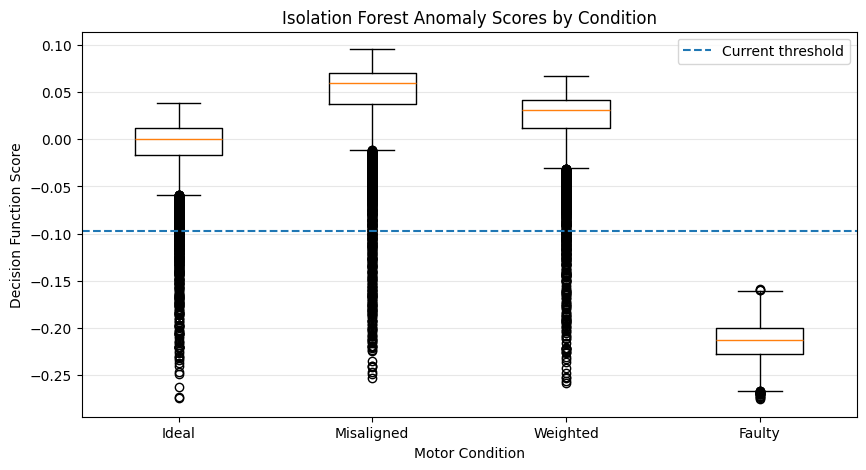

In [35]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

conditions = ["Ideal", "Misaligned", "Weighted", "Faulty"]

data = [
    score_analysis.loc[
        score_analysis["condition"] == c,
        "anomaly_score"
    ].values
    for c in conditions
]

plt.boxplot(data, tick_labels=conditions)
plt.axhline(
    anomaly_threshold,
    linestyle="--",
    label="Current threshold"
)

plt.title("Isolation Forest Anomaly Scores by Condition")
plt.ylabel("Decision Function Score")
plt.xlabel("Motor Condition")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.show()

In [36]:
# Condition-wise anomaly detection breakdown

evaluation_df = score_analysis.copy()

evaluation_df["predicted_anomaly"] = (
    evaluation_df["anomaly_score"] < anomaly_threshold
)

condition_detection = evaluation_df.groupby(
    "condition"
)["predicted_anomaly"].agg(
    total_windows="count",
    detected_anomalies="sum"
)

condition_detection["detection_rate_%"] = (
    condition_detection["detected_anomalies"] /
    condition_detection["total_windows"] * 100
)

condition_detection["normal_rate_%"] = (
    100 - condition_detection["detection_rate_%"]
)

display(condition_detection.round(2))

,total_windows,detected_anomalies,detection_rate_%,normal_rate_%
condition,,,,
Faulty,6000,6000,100.00,0.00
Ideal,6000,300,5.00,95.00
Misaligned,6000,196,3.27,96.73
Weighted,6000,203,3.38,96.62


In [37]:
condition_detection = evaluation_df.groupby(
    "condition"
)["predicted_anomaly"].agg(
    total_windows="count",
    detected_anomalies="sum"
)

condition_detection["detection_rate_%"] = (
    condition_detection["detected_anomalies"] /
    condition_detection["total_windows"] * 100
)

display(condition_detection.round(2))

,total_windows,detected_anomalies,detection_rate_%
condition,,,
Faulty,6000,6000,100.00
Ideal,6000,300,5.00
Misaligned,6000,196,3.27
Weighted,6000,203,3.38


In [38]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)

threshold_results = []

# Thresholds calibrated from different percentiles
percentiles = [1, 2, 5, 10, 15, 20, 25, 30]

for percentile in percentiles:

    threshold = np.percentile(
        ideal_val_scores,
        percentile
    )

    predictions = (val_scores < threshold).astype(int)

    threshold_results.append({
        "Ideal percentile": percentile,
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_true_if, predictions),
        "Precision": precision_score(
            y_true_if, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true_if, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_true_if, predictions, zero_division=0
        ),
        "False alarms on Ideal (%)": (
            np.mean(
                predictions[y_true_if == 0]
            ) * 100
        )
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

,Ideal percentile,Threshold,Accuracy,Precision,Recall,F1,False alarms on Ideal (%)
0,1,-0.1772,0.4965,0.9901,0.3319,0.4972,1.0
1,2,-0.1429,0.5032,0.9810,0.3443,0.5097,2.0
2,5,-0.0973,0.5041,0.9552,0.3555,0.5182,5.0
3,10,-0.0564,0.5055,0.9182,0.3741,0.5316,10.0
4,15,-0.0339,0.5079,0.8874,0.3939,0.5456,15.0
5,20,-0.0231,0.5021,0.8580,0.4028,0.5483,20.0
6,25,-0.0165,0.4942,0.8307,0.4089,0.5480,25.0
7,30,-0.0114,0.4864,0.8059,0.4152,0.5480,30.0


In [39]:
import numpy as np
import pandas as pd

# Ideal-only training data
X_ideal_mad = features_df.loc[
    ideal_train_mask,
    selected_features
].copy()

# Calculate median and MAD for every feature
feature_medians = X_ideal_mad.median()

feature_mads = (
    X_ideal_mad - feature_medians
).abs().median()

print("Healthy baseline created!")

print("\nFeature Medians:")
display(feature_medians)

print("\nFeature MAD:")
display(feature_mads)

Healthy baseline created!

Feature Medians:


,0
mean,-8.485000
rms,22.823059
peak_to_peak,168.000000
kurtosis,3.519529
crest_factor,3.971554



Feature MAD:


,0
mean,1.360500
rms,11.182054
peak_to_peak,98.000000
kurtosis,0.404394
crest_factor,0.559481


In [40]:
# Calculate robust Z-scores for validation data
X_val_mad = X_val_if.copy()

robust_z = (
    0.6745 * (X_val_mad - feature_medians)
    / feature_mads
)

# Absolute deviation from healthy baseline
robust_z_abs = robust_z.abs()

# Maximum deviation across all features
mad_anomaly_scores = robust_z_abs.max(axis=1)

# Count features exceeding the conventional 3.5 threshold
mad_anomaly_flags = (robust_z_abs > 3.5).sum(axis=1)

print("Median + MAD scoring completed!")

print("\nRobust Z-score summary:")
display(robust_z_abs.describe())

print("\nAnomaly score summary:")
display(mad_anomaly_scores.describe())

print("\nFeature-wise exceedance counts:")
display(mad_anomaly_flags.value_counts().sort_index())

Median + MAD scoring completed!

Robust Z-score summary:


,mean,rms,peak_to_peak,kurtosis,crest_factor
count,24000.000000,24000.000000,24000.000000,24000.000000,24000.000000
mean,1.039362,6.495930,8.874970,4.345904,1.394936
std,0.764718,10.309843,14.701448,6.221073,1.336973
min,0.000000,0.167222,0.000000,0.000001,0.000043
25%,0.388191,0.488931,0.309719,0.529547,0.403203
50%,0.774398,0.626660,0.646969,0.988432,0.845089
75%,1.682160,6.228400,9.721747,6.854024,2.174816
max,3.583452,31.097618,56.995250,61.459588,8.881992



Anomaly score summary:


,0
count,24000.000000
mean,10.000526
std,14.361582
min,0.264996
25%,0.864141
50%,1.915227
75%,21.839841
max,61.459588



Feature-wise exceedance counts:


,count
0,16183
1,1213
2,508
3,4405
4,1690
5,1


In [41]:
# Convert actual conditions into binary labels
# Ideal = normal (0), all other conditions = abnormal (1)

y_mad_true = (y_val_if != "Ideal").astype(int)

# Initial anomaly decision threshold
MAD_THRESHOLD = 3.5

y_mad_pred = (mad_anomaly_scores > MAD_THRESHOLD).astype(int)

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("MEDIAN + MAD EVALUATION")
print("-" * 45)

print("Accuracy:", accuracy_score(y_mad_true, y_mad_pred))
print("Precision:", precision_score(y_mad_true, y_mad_pred))
print("Recall:", recall_score(y_mad_true, y_mad_pred))
print("F1 Score:", f1_score(y_mad_true, y_mad_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_mad_true, y_mad_pred))

print("\nClassification Report:")
print(classification_report(
    y_mad_true,
    y_mad_pred,
    target_names=["Ideal (Normal)", "Abnormal"]
))

# Detection rate for each condition
mad_results = pd.DataFrame({
    "condition": y_val_if,
    "predicted_anomaly": y_mad_pred
})

print("\nDetection Rate by Condition:")
display(
    mad_results.groupby("condition")["predicted_anomaly"]
    .agg(["sum", "count", "mean"])
    .rename(columns={"mean": "detection_rate"})
)

MEDIAN + MAD EVALUATION
---------------------------------------------
Accuracy: 0.5312083333333333
Precision: 0.9316873480875016
Recall: 0.4046111111111111
F1 Score: 0.564201882480536

Confusion Matrix:
[[ 5466   534]
 [10717  7283]]

Classification Report:
                precision    recall  f1-score   support

Ideal (Normal)       0.34      0.91      0.49      6000
      Abnormal       0.93      0.40      0.56     18000

      accuracy                           0.53     24000
     macro avg       0.63      0.66      0.53     24000
  weighted avg       0.78      0.53      0.55     24000


Detection Rate by Condition:


,sum,count,detection_rate
condition,,,
Faulty,6000,6000,1.000000
Ideal,534,6000,0.089000
Misaligned,693,6000,0.115500
Weighted,590,6000,0.098333


In [42]:
thresholds = [2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0, 6.0, 8.0]

threshold_results = []

for threshold in thresholds:

    predictions = (
        mad_anomaly_scores > threshold
    ).astype(int)

    threshold_results.append({
        "threshold": threshold,
        "accuracy": accuracy_score(y_mad_true, predictions),
        "precision": precision_score(y_mad_true, predictions),
        "recall": recall_score(y_mad_true, predictions),
        "f1": f1_score(y_mad_true, predictions),
        "ideal_false_alarm_rate": (
            predictions[y_mad_true == 0].mean()
        ),
        "faulty_detection_rate": (
            predictions[y_val_if == "Faulty"].mean()
        ),
        "misaligned_detection_rate": (
            predictions[y_val_if == "Misaligned"].mean()
        ),
        "weighted_detection_rate": (
            predictions[y_val_if == "Weighted"].mean()
        )
    })

threshold_results_df = pd.DataFrame(threshold_results)

display(
    threshold_results_df.round(4)
)

,threshold,accuracy,precision,recall,f1,ideal_false_alarm_rate,faulty_detection_rate,misaligned_detection_rate,weighted_detection_rate
0,2.0,0.4447,0.7021,0.4510,0.5492,0.5742,1.0,0.1862,0.1668
1,2.5,0.5115,0.8410,0.4299,0.5690,0.2438,1.0,0.1558,0.1340
2,3.0,0.5360,0.9226,0.4163,0.5737,0.1048,1.0,0.1347,0.1143
3,3.5,0.5312,0.9317,0.4046,0.5642,0.0890,1.0,0.1155,0.0983
4,4.0,0.5265,0.9372,0.3952,0.5560,0.0795,1.0,0.1007,0.0850
5,4.5,0.5232,0.9427,0.3878,0.5496,0.0707,1.0,0.0892,0.0743
6,5.0,0.5203,0.9477,0.3814,0.5439,0.0632,1.0,0.0788,0.0655
7,6.0,0.5160,0.9567,0.3716,0.5352,0.0505,1.0,0.0638,0.0508
8,8.0,0.5109,0.9698,0.3590,0.5240,0.0335,1.0,0.0435,0.0335


In [43]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)
import pandas as pd

# Isolation Forest predictions
if_predictions = (
    val_scores < anomaly_threshold
).astype(int)

# Median + MAD predictions at threshold 3.0
mad_predictions = (
    mad_anomaly_scores > 3.0
).astype(int)

comparison = []

for name, predictions in [
    ("Isolation Forest", if_predictions),
    ("Median + MAD", mad_predictions)
]:
    comparison.append({
        "Model": name,
        "Accuracy": accuracy_score(y_mad_true, predictions),
        "Precision": precision_score(y_mad_true, predictions),
        "Recall": recall_score(y_mad_true, predictions),
        "F1": f1_score(y_mad_true, predictions),
        "Ideal False Alarm Rate": predictions[
            y_mad_true == 0
        ].mean()
    })

comparison_df = pd.DataFrame(comparison)

display(comparison_df.round(4))

,Model,Accuracy,Precision,Recall,F1,Ideal False Alarm Rate
0,Isolation Forest,0.5041,0.9552,0.3555,0.5182,0.0500
1,Median + MAD,0.5360,0.9226,0.4163,0.5737,0.1048


In [44]:
import numpy as np
import pandas as pd

from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

# 1. Train Extra Trees on the training data
et_model = ExtraTreesClassifier(
    n_estimators=200,
    max_depth=15,
    min_samples_split=10,
    min_samples_leaf=5,
    max_features="sqrt",
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

et_model.fit(X_train, y_train)

# 2. Get probability predictions from both models
rf_prob = rf_model.predict_proba(X_test)
et_prob = et_model.predict_proba(X_test)

# 3. Align class probabilities
assert np.array_equal(rf_model.classes_, et_model.classes_)

# 4. Combine predictions using soft voting
combined_prob = (rf_prob + et_prob) / 2

combined_predictions = rf_model.classes_[
    np.argmax(combined_prob, axis=1)
]

# 5. Calculate ONE combined test accuracy
combined_accuracy = accuracy_score(
    y_test,
    combined_predictions
)

combined_f1 = f1_score(
    y_test,
    combined_predictions,
    average="macro"
)

print("=" * 50)
print("SHAKESENSE — COMBINED MODEL TEST RESULTS")
print("=" * 50)

print(f"Combined Test Accuracy: {combined_accuracy * 100:.2f}%")
print(f"Combined Macro F1:      {combined_f1 * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_test, combined_predictions))

print("\nCombined Confusion Matrix:")
print(confusion_matrix(y_test, combined_predictions))

SHAKESENSE — COMBINED MODEL TEST RESULTS
Combined Test Accuracy: 48.42%
Combined Macro F1:      36.97%

Classification Report:
              precision    recall  f1-score   support

      Faulty       0.99      1.00      1.00      6000
       Ideal       0.00      0.00      0.00      6000
  Misaligned       0.32      0.94      0.48      6000
    Weighted       1.00      0.00      0.00      6000

    accuracy                           0.48     24000
   macro avg       0.58      0.48      0.37     24000
weighted avg       0.58      0.48      0.37     24000


Combined Confusion Matrix:
[[6000    0    0    0]
 [   4    0 5996    0]
 [   5  377 5618    0]
 [  24  213 5760    3]]


In [45]:
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

# Predictions on the same test dataset
rf_test_pred = rf_model.predict(X_test)
et_test_pred = et_model.predict(X_test)

results = pd.DataFrame([
    {
        "Model": "Random Forest",
        "Accuracy": accuracy_score(y_test, rf_test_pred),
        "Macro F1": f1_score(
            y_test, rf_test_pred, average="macro"
        )
    },
    {
        "Model": "Extra Trees",
        "Accuracy": accuracy_score(y_test, et_test_pred),
        "Macro F1": f1_score(
            y_test, et_test_pred, average="macro"
        )
    },
    {
        "Model": "RF + ET Ensemble",
        "Accuracy": accuracy_score(y_test, combined_predictions),
        "Macro F1": f1_score(
            y_test, combined_predictions, average="macro"
        )
    }
])

display(results.round(4))

,Model,Accuracy,Macro F1
0,Random Forest,0.4845,0.3701
1,Extra Trees,0.4852,0.3730
2,RF + ET Ensemble,0.4842,0.3697


In [46]:
from sklearn.metrics import classification_report
import pandas as pd

models = {
    "Random Forest": rf_model,
    "Extra Trees": et_model
}

for name, model in models.items():
    print(f"\n{'='*50}")
    print(name)
    print("="*50)

    predictions = model.predict(X_test)

    print(classification_report(
        y_test,
        predictions,
        zero_division=0
    ))


Random Forest
              precision    recall  f1-score   support

      Faulty       1.00      1.00      1.00      6000
       Ideal       0.00      0.00      0.00      6000
  Misaligned       0.32      0.94      0.48      6000
    Weighted       0.50      0.00      0.00      6000

    accuracy                           0.48     24000
   macro avg       0.46      0.48      0.37     24000
weighted avg       0.46      0.48      0.37     24000


Extra Trees
              precision    recall  f1-score   support

      Faulty       0.98      1.00      0.99      6000
       Ideal       0.09      0.01      0.02      6000
  Misaligned       0.32      0.93      0.48      6000
    Weighted       1.00      0.00      0.00      6000

    accuracy                           0.49     24000
   macro avg       0.60      0.49      0.37     24000
weighted avg       0.60      0.49      0.37     24000



In [47]:
import pandas as pd
import numpy as np

train_analysis = train_df.copy()
test_analysis = test_df.copy()

features = selected_features

train_stats = train_analysis.groupby("condition")[features].agg(
    ["median", lambda x: x.quantile(0.25),
     lambda x: x.quantile(0.75)]
)

test_stats = test_analysis.groupby("condition")[features].agg(
    ["median", lambda x: x.quantile(0.25),
     lambda x: x.quantile(0.75)]
)

for feature in features:
    print(f"\n{'='*55}")
    print("FEATURE:", feature)
    print("="*55)

    comparison = pd.DataFrame({
        "Train Median": train_analysis.groupby("condition")[feature].median(),
        "Test Median": test_analysis.groupby("condition")[feature].median(),
        "Train IQR": (
            train_analysis.groupby("condition")[feature].quantile(.75)
            - train_analysis.groupby("condition")[feature].quantile(.25)
        ),
        "Test IQR": (
            test_analysis.groupby("condition")[feature].quantile(.75)
            - test_analysis.groupby("condition")[feature].quantile(.25)
        )
    })

    display(comparison.round(3))


FEATURE: mean


,Train Median,Test Median,Train IQR,Test IQR
condition,,,,
Faulty,-9.798,-11.736,2.352,2.184
Ideal,-8.485,-11.840,4.642,1.001
Misaligned,-9.032,-10.349,1.687,1.347
Weighted,-8.424,-10.552,1.986,1.453



FEATURE: rms


,Train Median,Test Median,Train IQR,Test IQR
condition,,,,
Faulty,260.499,1215.908,548.060,92.974
Ideal,22.823,55.901,33.568,4.902
Misaligned,21.132,55.647,32.802,4.534
Weighted,23.100,66.677,38.653,4.589



FEATURE: peak_to_peak


,Train Median,Test Median,Train IQR,Test IQR
condition,,,,
Faulty,3125.0,12384.0,6892.75,1576.0
Ideal,168.0,497.0,299.00,218.0
Misaligned,163.0,480.0,316.00,196.0
Weighted,172.0,553.0,355.00,230.0



FEATURE: kurtosis


,Train Median,Test Median,Train IQR,Test IQR
condition,,,,
Faulty,11.953,8.065,8.382,1.200
Ideal,3.520,4.192,1.021,2.312
Misaligned,3.734,3.977,1.231,1.833
Weighted,3.385,3.665,0.858,1.654



FEATURE: crest_factor


,Train Median,Test Median,Train IQR,Test IQR
condition,,,,
Faulty,6.525,5.336,2.059,0.597
Ideal,3.972,4.956,1.218,2.129
Misaligned,3.946,4.790,1.184,1.941
Weighted,3.765,4.656,1.053,2.039


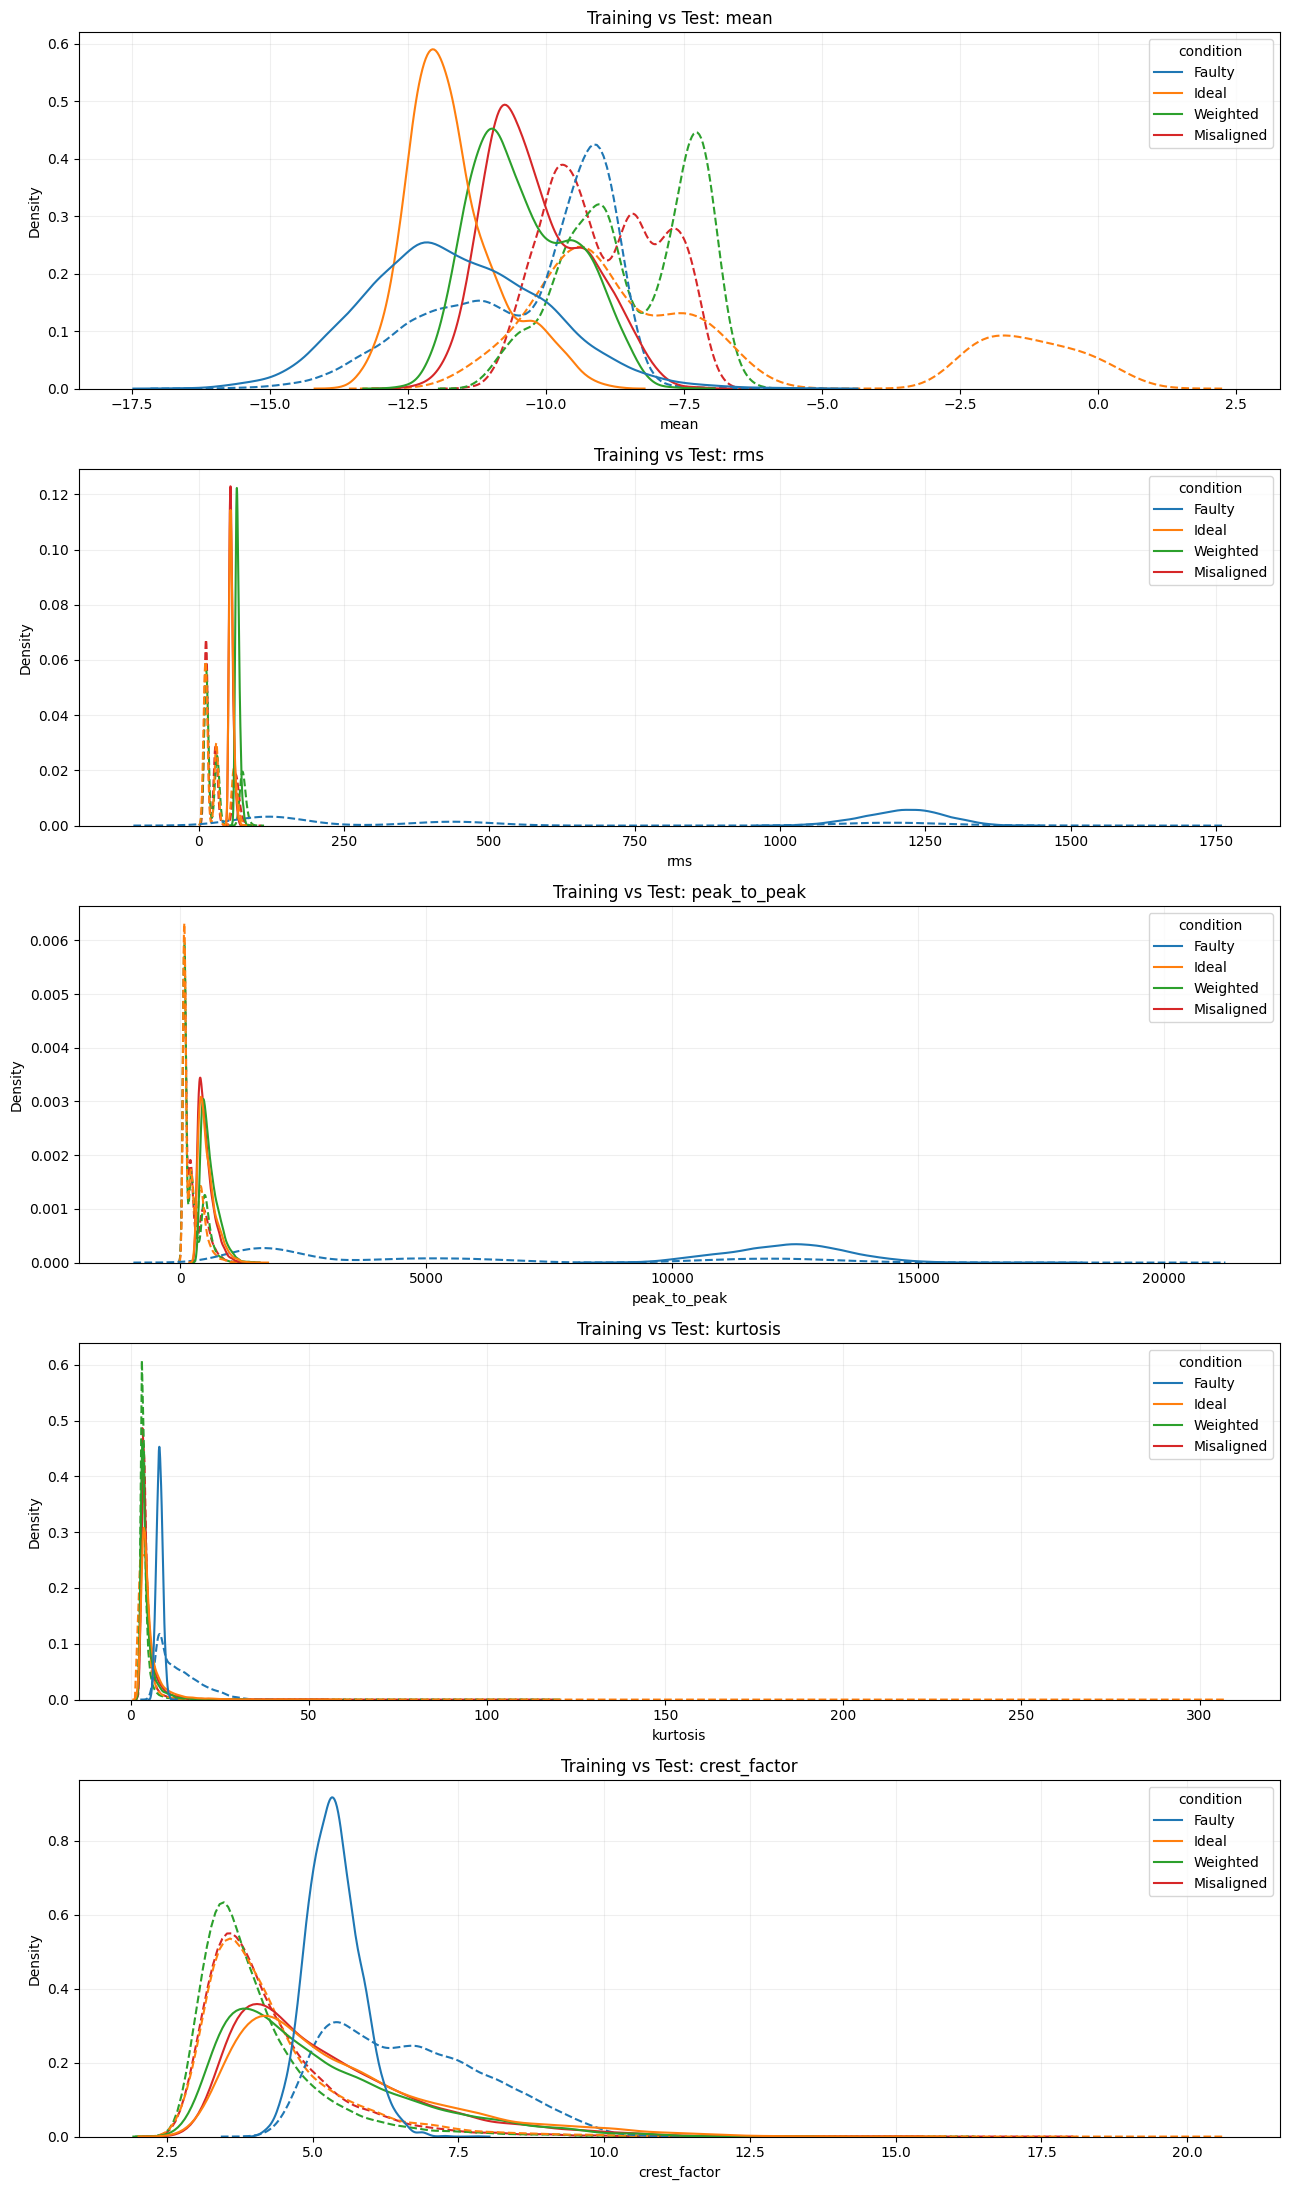

In [48]:
import matplotlib.pyplot as plt
import seaborn as sns

features = selected_features
conditions = ["Faulty", "Ideal", "Misaligned", "Weighted"]

fig, axes = plt.subplots(
    len(features), 1,
    figsize=(13, 22)
)

for ax, feature in zip(axes, features):

    sns.kdeplot(
        data=train_df,
        x=feature,
        hue="condition",
        common_norm=False,
        ax=ax,
        linestyle="--"
    )

    sns.kdeplot(
        data=test_df,
        x=feature,
        hue="condition",
        common_norm=False,
        ax=ax,
        linestyle="-"
    )

    ax.set_title(f"Training vs Test: {feature}")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [49]:
import numpy as np
import pandas as pd

for df in [train_df, val_df, test_df]:
    df["ac_rms"] = np.sqrt(
        np.maximum(df["rms"]**2 - df["mean"]**2, 0)
    )

print("AC RMS feature comparison")

for name, df in [
    ("TRAIN", train_df),
    ("VALIDATION", val_df),
    ("TEST", test_df)
]:
    print(f"\n{name}")
    display(
        df.groupby("condition")[
            ["rms", "ac_rms", "peak_to_peak"]
        ].median().round(3)
    )

AC RMS feature comparison

TRAIN


,rms,ac_rms,peak_to_peak
condition,,,
Faulty,260.499,260.276,3125.0
Ideal,22.823,21.835,168.0
Misaligned,21.132,19.211,163.0
Weighted,23.100,21.386,172.0



VALIDATION


,rms,ac_rms,peak_to_peak
condition,,,
Faulty,422.128,421.984,4981.0
Ideal,31.829,31.500,231.0
Misaligned,30.504,29.193,221.0
Weighted,33.364,32.546,243.0



TEST


,rms,ac_rms,peak_to_peak
condition,,,
Faulty,1215.908,1215.869,12384.0
Ideal,55.901,54.653,497.0
Misaligned,55.647,54.706,480.0
Weighted,66.677,65.822,553.0


In [50]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report
import pandas as pd

feature_sets = {
    "Original": [
        "mean", "rms", "peak_to_peak",
        "kurtosis", "crest_factor"
    ],
    "AC RMS replacing RMS": [
        "mean", "ac_rms", "peak_to_peak",
        "kurtosis", "crest_factor"
    ],
    "AC RMS without mean": [
        "ac_rms", "peak_to_peak",
        "kurtosis", "crest_factor"
    ]
}

results = []

for name, features in feature_sets.items():

    model = RandomForestClassifier(
        n_estimators=200,
        max_depth=15,
        min_samples_split=10,
        min_samples_leaf=5,
        max_features="sqrt",
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )

    model.fit(train_df[features], train_df["condition"])

    predictions = model.predict(val_df[features])

    results.append({
        "Feature Set": name,
        "Accuracy": accuracy_score(
            val_df["condition"], predictions
        ),
        "Macro F1": f1_score(
            val_df["condition"], predictions,
            average="macro"
        )
    })

display(pd.DataFrame(results).round(4))

,Feature Set,Accuracy,Macro F1
0,Original,0.8342,0.8257
1,AC RMS replacing RMS,0.8449,0.8341
2,AC RMS without mean,0.5654,0.5074


In [53]:
print("Available columns:")
print(features_df.columns.tolist())

print("\nSample rows:")
display(features_df.head())

print("\nUnique recording IDs:")
print(features_df["recording_id"].nunique())

Available columns:
['condition', 'speed', 'position', 'window', 'mean', 'std', 'rms', 'peak_to_peak', 'kurtosis', 'crest_factor', 'recording_id']

Sample rows:


,condition,speed,position,window,mean,std,rms,peak_to_peak,kurtosis,crest_factor,recording_id
0,Faulty,10,2,0,-9.592,102.329163,102.777741,1249.0,12.269858,6.499462,Faulty_10rev_2
1,Faulty,10,2,1,-9.891,76.680487,77.315775,1022.0,14.671248,7.695713,Faulty_10rev_2
2,Faulty,10,2,2,-9.708,121.195391,121.583584,1792.0,19.426284,8.537337,Faulty_10rev_2
3,Faulty,10,2,3,-9.562,126.037622,126.399818,1853.0,19.161592,8.037986,Faulty_10rev_2
4,Faulty,10,2,4,-9.762,142.450417,142.784516,2218.0,21.473224,8.250194,Faulty_10rev_2



Unique recording IDs:
24


In [54]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd
import numpy as np

# Calculate AC RMS for the complete dataset
features_df["ac_rms"] = np.sqrt(
    np.maximum(
        features_df["rms"]**2 - features_df["mean"]**2,
        0
    )
)

feature_sets = {
    "Original": [
        "mean", "rms", "peak_to_peak",
        "kurtosis", "crest_factor"
    ],
    "AC RMS": [
        "mean", "ac_rms", "peak_to_peak",
        "kurtosis", "crest_factor"
    ]
}

results = []

for (speed, position), test_fold in features_df.groupby(
    ["speed", "position"]
):

    train_fold = features_df[
        ~(
            (features_df["speed"] == speed) &
            (features_df["position"] == position)
        )
    ]

    for feature_name, features in feature_sets.items():

        model = RandomForestClassifier(
            n_estimators=200,
            max_depth=15,
            min_samples_split=10,
            min_samples_leaf=5,
            max_features="sqrt",
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        )

        model.fit(
            train_fold[features],
            train_fold["condition"]
        )

        predictions = model.predict(test_fold[features])

        results.append({
            "Speed": speed,
            "Position": position,
            "Feature Set": feature_name,
            "Accuracy": accuracy_score(
                test_fold["condition"], predictions
            ),
            "Macro F1": f1_score(
                test_fold["condition"],
                predictions,
                average="macro"
            )
        })

cv_comparison = pd.DataFrame(results)

print("INDIVIDUAL FOLD RESULTS")
display(
    cv_comparison.sort_values(
        ["Speed", "Position", "Feature Set"]
    ).round(4)
)

print("\nAVERAGE PERFORMANCE")
display(
    cv_comparison.groupby("Feature Set")[
        ["Accuracy", "Macro F1"]
    ].agg(["mean", "std"]).round(4)
)

INDIVIDUAL FOLD RESULTS


,Speed,Position,Feature Set,Accuracy,Macro F1
1,10,1,AC RMS,0.7492,0.6678
0,10,1,Original,0.7486,0.6683
3,10,2,AC RMS,0.4994,0.3747
2,10,2,Original,0.4992,0.3746
5,20,1,AC RMS,0.8460,0.8369
4,20,1,Original,0.8468,0.8403
7,20,2,AC RMS,0.5003,0.3756
6,20,2,Original,0.5005,0.3761
9,30,1,AC RMS,0.5484,0.4614
8,30,1,Original,0.5497,0.4639



AVERAGE PERFORMANCE


Accuracy         Macro F1        
                mean     std     mean     std
Feature Set                                  
AC RMS        0.6048  0.1539   0.5145  0.1948
Original      0.6050  0.1540   0.5156  0.1959

In [55]:
import numpy as np
import joblib
import os
import zipfile

from sklearn.ensemble import RandomForestClassifier, IsolationForest

# ==========================================
# 1. COMMON FEATURES
# ==========================================

features = [
    "mean",
    "rms",
    "peak_to_peak",
    "kurtosis",
    "crest_factor"
]

# ==========================================
# 2. GLOBAL RANDOM FOREST
# ==========================================

global_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=15,
    min_samples_split=10,
    min_samples_leaf=5,
    max_features="sqrt",
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

global_model.fit(train_df[features], y_train)

joblib.dump({
    "model": global_model,
    "features": features,
    "classes": list(global_model.classes_),
    "model_type": "Random Forest",
    "purpose": "Four-class motor condition classification"
}, "shakesense_global_rf.pkl")

print("1. Global Random Forest saved.")

# ==========================================
# 3. ISOLATION FOREST
# ==========================================

ideal_train = train_df[
    train_df["condition"] == "Ideal"
]

isolation_model = IsolationForest(
    n_estimators=200,
    max_samples="auto",
    contamination="auto",
    max_features=1.0,
    random_state=42,
    n_jobs=-1
)

isolation_model.fit(ideal_train[features])

# Calibrate threshold using Ideal validation recordings
ideal_val = val_df[
    val_df["condition"] == "Ideal"
]

isolation_val_scores = isolation_model.decision_function(
    ideal_val[features]
)

isolation_threshold = float(
    np.percentile(isolation_val_scores, 5)
)

joblib.dump({
    "model": isolation_model,
    "features": features,
    "threshold": isolation_threshold,
    "normal_class": "Ideal",
    "purpose": "Unsupervised vibration anomaly detection"
}, "shakesense_isolation_forest.pkl")

print("2. Isolation Forest saved.")
print("Isolation threshold:", isolation_threshold)

# ==========================================
# 4. MEDIAN + MAD
# ==========================================

healthy_data = ideal_train[features]

feature_medians = healthy_data.median()
feature_mads = (healthy_data - feature_medians).abs().median()

if (feature_mads == 0).any():
    raise ValueError("Zero MAD detected. Check baseline features.")

mad_threshold = 3.0

joblib.dump({
    "feature_names": features,
    "medians": feature_medians.to_dict(),
    "mads": feature_mads.to_dict(),
    "threshold": mad_threshold,
    "robust_z_constant": 0.6745,
    "purpose": "Statistical vibration anomaly detection"
}, "shakesense_median_mad.pkl")

print("3. Median + MAD baseline saved.")

# ==========================================
# 5. PACKAGE ALL THREE
# ==========================================

model_files = [
    "shakesense_global_rf.pkl",
    "shakesense_isolation_forest.pkl",
    "shakesense_median_mad.pkl"
]

with zipfile.ZipFile(
    "ShakeSense_Trained_Models.zip", "w"
) as zipf:
    for file in model_files:
        zipf.write(file)

print("\nALL THREE APPROACHES SAVED SUCCESSFULLY.")

for file in model_files:
    print(file, "->", round(os.path.getsize(file)/1024, 2), "KB")

print("\nZIP: ShakeSense_Trained_Models.zip")

from google.colab import files
files.download("ShakeSense_Trained_Models.zip")

1. Global Random Forest saved.
2. Isolation Forest saved.
Isolation threshold: -0.0972528596378597
3. Median + MAD baseline saved.

ALL THREE APPROACHES SAVED SUCCESSFULLY.
shakesense_global_rf.pkl -> 43317.29 KB
shakesense_isolation_forest.pkl -> 2359.33 KB
shakesense_median_mad.pkl -> 0.32 KB

ZIP: ShakeSense_Trained_Models.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>